In [5]:
!pip install -q kaggle
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os

folder = "/content/drive/MyDrive/PhD/HLSTM-GRU"
os.makedirs(folder, exist_ok=True)

print("Folder ready:", folder)

Folder ready: /content/drive/MyDrive/PhD/HLSTM-GRU


In [8]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured successfully.")

Kaggle API configured successfully.


In [9]:
!mkdir -p /content/bbc_dataset

!kaggle datasets download \
    -d imumerfarooq/bbc-news-summary \
    -p /content/bbc_dataset

Dataset URL: https://www.kaggle.com/datasets/imumerfarooq/bbc-news-summary
License(s): unknown
100% 8.91M/8.91M [00:00<00:00, 49.7MB/s]



In [10]:
import zipfile
import os

zip_path = "/content/bbc_dataset/bbc-news-summary.zip"
extract_path = "/content/bbc_dataset/extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [11]:
import os

folder = "/content/drive/MyDrive/PhD/HLSTM-GRU"

print("Files in folder:")
for f in os.listdir(folder):
    print(f)

Files in folder:
lstm_attention_proposed_best.keras
attention_training_history.pkl
hlstm_gru_training_history.pkl
hlstm_gru_best.keras
hlstm_gru_vocabulary.pkl
pso_best_mask.npy
pso_fitness_history.npy
pso_results.pkl
figure_training_validation_loss.png
figure_training_validation_loss.pdf
figure_rouge_comparison.png
figure_rouge_comparison.pdf
figure_pso_convergence.png
figure_pso_convergence.pdf
figure_feature_selection.png
figure_feature_selection.pdf
Figure_Training_Validation_Loss.png
Figure_Training_Validation_Loss.pdf
Figure_ROUGE_Comparison.png
Figure_ROUGE_Comparison.pdf
Figure_PSO_Convergence.png
Figure_PSO_Convergence.pdf
Figure_Feature_Selection.png
Figure_Feature_Selection.pdf
revision_results


In [12]:
import os

folder = "/content/drive/MyDrive/PhD/HLSTM-GRU"

for f in os.listdir(folder):
    path = os.path.join(folder, f)
    print(f"{f}  →  {os.path.getsize(path) / (1024**2):.2f} MB")

lstm_attention_proposed_best.keras  →  179.19 MB
attention_training_history.pkl  →  0.00 MB
hlstm_gru_training_history.pkl  →  0.00 MB
hlstm_gru_best.keras  →  301.34 MB
hlstm_gru_vocabulary.pkl  →  0.77 MB
pso_best_mask.npy  →  0.00 MB
pso_fitness_history.npy  →  0.00 MB
pso_results.pkl  →  0.00 MB
figure_training_validation_loss.png  →  0.29 MB
figure_training_validation_loss.pdf  →  0.01 MB
figure_rouge_comparison.png  →  0.20 MB
figure_rouge_comparison.pdf  →  0.01 MB
figure_pso_convergence.png  →  0.28 MB
figure_pso_convergence.pdf  →  0.01 MB
figure_feature_selection.png  →  0.22 MB
figure_feature_selection.pdf  →  0.01 MB
Figure_Training_Validation_Loss.png  →  0.29 MB
Figure_Training_Validation_Loss.pdf  →  0.01 MB
Figure_ROUGE_Comparison.png  →  0.20 MB
Figure_ROUGE_Comparison.pdf  →  0.01 MB
Figure_PSO_Convergence.png  →  0.28 MB
Figure_PSO_Convergence.pdf  →  0.01 MB
Figure_Feature_Selection.png  →  0.20 MB
Figure_Feature_Selection.pdf  →  0.01 MB
revision_results  →  0.00 M

In [13]:
import os

print("Folders/files under /content:\n")

for root, dirs, files in os.walk("/content"):
    if files:
        print(root)
        print("  Files:", files[:5])

Folders/files under /content:

/content
  Files: ['kaggle (1).json', 'kaggle.json']
/content/.config
  Files: ['.last_update_check.json', 'hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'config_sentinel', '.last_opt_in_prompt.yaml', 'default_configs.db']
/content/.config/configurations
  Files: ['config_default']
/content/.config/logs/2026.10.21
  Files: ['13.27.58.650478.log', '13.28.04.564766.log', '13.27.51.774504.log', '13.27.57.480371.log', '13.28.05.116687.log']
/content/bbc_dataset
  Files: ['bbc-news-summary.zip']
/content/bbc_dataset/extracted/BBC News Summary/Summaries/business
  Files: ['348.txt', '126.txt', '337.txt', '244.txt', '130.txt']
/content/bbc_dataset/extracted/BBC News Summary/Summaries/politics
  Files: ['348.txt', '126.txt', '337.txt', '244.txt', '130.txt']
/content/bbc_dataset/extracted/BBC News Summary/Summaries/tech
  Files: ['348.txt', '126.txt', '337.txt', '244.txt', '130.txt']
/content/bbc_dataset/extracted/BBC News Summary/Summaries/spor

In [14]:
import os
import pandas as pd

BASE_PATH = "/content/bbc_dataset/extracted/BBC News Summary"

articles_path = os.path.join(BASE_PATH, "News Articles")
summaries_path = os.path.join(BASE_PATH, "Summaries")

data = []

categories = ["business", "entertainment", "politics", "sport", "tech"]

for category in categories:
    article_dir = os.path.join(articles_path, category)
    summary_dir = os.path.join(summaries_path, category)

    for filename in os.listdir(article_dir):
        if filename.endswith(".txt"):
            article_file = os.path.join(article_dir, filename)
            summary_file = os.path.join(summary_dir, filename)

            if os.path.exists(summary_file):
                with open(article_file, "r", encoding="utf-8", errors="ignore") as f:
                    article = f.read().strip()

                with open(summary_file, "r", encoding="utf-8", errors="ignore") as f:
                    summary = f.read().strip()

                data.append({
                    "id": filename.replace(".txt", ""),
                    "category": category,
                    "article": article,
                    "summary": summary
                })

df = pd.DataFrame(data)

print("Total records:", len(df))
print("Categories:")
print(df["category"].value_counts())
print("\nData shape:", df.shape)
df.head()

Total records: 2225
Categories:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

Data shape: (2225, 4)


,id,category,article,summary
0,348,business,US to probe airline travel chaos\n\nThe US gov...,"Ground crews at US Airways, the seventh-larges..."
1,126,business,"Barclays profits hit record level\n\nBarclays,...",Earnings at Barclays Capital investment bank r...
2,337,business,Building giant in asbestos payout\n\nAustralia...,"In 2001, the company set up a fund to compensa..."
3,244,business,Market unfazed by Aurora setback\n\nAs the Aur...,"Despite its string of bad luck, he pointed out..."
4,130,business,Aviation firms eye booming India\n\nIndia's de...,The US company also said it had agreed with a ...


In [15]:
from sklearn.model_selection import train_test_split

# First split: 80% train, 20% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["category"]
)

# Split the temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["category"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Train: 1780
Validation: 222
Test: 223

Total: 2225


In [16]:
import os
import re
import pandas as pd

# ============================================================
# PATHS
# ============================================================

BASE_PATH = "/content/bbc_dataset/extracted/BBC News Summary"

NEWS_PATH = os.path.join(BASE_PATH, "News Articles")
SUMMARY_PATH = os.path.join(BASE_PATH, "Summaries")

print("News path:", NEWS_PATH)
print("Summary path:", SUMMARY_PATH)

# Check folders
print("\nCategories:")
print(os.listdir(NEWS_PATH))


# ============================================================
# CLEANING FUNCTION
# ============================================================

def clean_text(text):
    # Remove non-ASCII characters
    text = text.encode("ascii", "ignore").decode("ascii")

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove leading/trailing spaces
    text = text.strip()

    return text


# ============================================================
# LOAD BBC ARTICLES + HUMAN SUMMARIES
# ============================================================

categories = [
    "business",
    "entertainment",
    "politics",
    "sport",
    "tech"
]

records = []

for category in categories:

    article_dir = os.path.join(NEWS_PATH, category)
    summary_dir = os.path.join(SUMMARY_PATH, category)

    article_files = sorted(os.listdir(article_dir))

    for filename in article_files:

        article_file = os.path.join(article_dir, filename)
        summary_file = os.path.join(summary_dir, filename)

        # Only use files having both article and summary
        if not os.path.isfile(summary_file):
            continue

        try:
            with open(article_file, "r", encoding="utf-8", errors="ignore") as f:
                article = f.read()

            with open(summary_file, "r", encoding="utf-8", errors="ignore") as f:
                summary = f.read()

            article = clean_text(article)
            summary = clean_text(summary)

            # Skip empty records
            if not article or not summary:
                continue

            article_words = len(article.split())
            summary_words = len(summary.split())

            if summary_words == 0:
                continue

            compression_ratio = article_words / summary_words

            records.append({
                "id": len(records) + 1,
                "category": category,
                "article": article,
                "summary": summary,
                "article_words": article_words,
                "summary_words": summary_words,
                "compression_ratio": compression_ratio
            })

        except Exception as e:
            print("Error:", filename, e)


# ============================================================
# CREATE DATAFRAME
# ============================================================

df = pd.DataFrame(records)

print("\n" + "="*60)
print("CLEAN DATASET")
print("="*60)

print("Shape:", df.shape)
print("\nCategory distribution:")
print(df["category"].value_counts())

# Save
clean_csv = "/content/bbc_news_summary_clean.csv"
df.to_csv(clean_csv, index=False)

print("\nSaved:")
print(clean_csv)

News path: /content/bbc_dataset/extracted/BBC News Summary/News Articles
Summary path: /content/bbc_dataset/extracted/BBC News Summary/Summaries

Categories:
['business', 'politics', 'tech', 'sport', 'entertainment']

CLEAN DATASET
Shape: (2225, 7)

Category distribution:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

Saved:
/content/bbc_news_summary_clean.csv


In [17]:
import os
import re
import pandas as pd

BASE_PATH = "/content/bbc_dataset/extracted/BBC News Summary"

NEWS_PATH = os.path.join(BASE_PATH, "News Articles")
SUMMARY_PATH = os.path.join(BASE_PATH, "Summaries")


def clean_text(text):
    # Remove non-ASCII characters
    text = text.encode("ascii", "ignore").decode("ascii")

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove leading/trailing spaces
    text = text.strip()

    return text


categories = [
    "business",
    "entertainment",
    "politics",
    "sport",
    "tech"
]

records = []

for category in categories:

    article_dir = os.path.join(NEWS_PATH, category)
    summary_dir = os.path.join(SUMMARY_PATH, category)

    article_files = sorted(os.listdir(article_dir))

    for filename in article_files:

        article_file = os.path.join(article_dir, filename)
        summary_file = os.path.join(summary_dir, filename)

        # Only use files having both article and summary
        if not os.path.isfile(summary_file):
            continue

        try:
            with open(article_file, "r", encoding="utf-8", errors="ignore") as f:
                article = f.read()

            with open(summary_file, "r", encoding="utf-8", errors="ignore") as f:
                summary = f.read()

            article = clean_text(article)
            summary = clean_text(summary)

            # Skip empty records
            if not article or not summary:
                continue

            article_words = len(article.split())
            summary_words = len(summary.split())

            if summary_words == 0:
                continue

            compression_ratio = article_words / summary_words

            records.append({
                "id": len(records) + 1,
                "category": category,
                "article": article,
                "summary": summary,
                "article_words": article_words,
                "summary_words": summary_words,
                "compression_ratio": compression_ratio
            })

        except Exception as e:
            print("Error:", filename, e)


df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
print("\nCategory distribution:")
print(df["category"].value_counts())

Dataset shape: (2225, 7)

Category distribution:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

# First split: 80% train, 20% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["category"]
)

# Split temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["category"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Train: 1780
Validation: 222
Test: 223

Total: 2225


In [19]:
# ============================================================
# DEFINE SPECIAL TOKEN IDs
# ============================================================

MAX_ARTICLE_LEN = 400
MAX_SUMMARY_LEN = 120

PAD_ID = 0
UNK_ID = 1
START_ID = 2
END_ID = 3

print("Special tokens:")
print("<PAD>  :", PAD_ID)
print("<UNK>  :", UNK_ID)
print("<START>:", START_ID)
print("<END>  :", END_ID)

Special tokens:
<PAD>  : 0
<UNK>  : 1
<START>: 2
<END>  : 3


In [20]:
# ============================================================
# CELL 4: LOAD SAVED HLSTM-GRU MODEL
# ============================================================

import os
import tensorflow as tf
from tensorflow.keras.models import load_model

PROJECT_DIR = "/content/drive/MyDrive/PhD/HLSTM-GRU"

model_path = os.path.join(
    PROJECT_DIR,
    "hlstm_gru_best.keras"
)

print("Loading model from:")
print(model_path)

hlstm_gru_model = load_model(
    model_path,
    compile=False
)

print("\nModel loaded successfully.")
print("Total parameters:",
      hlstm_gru_model.count_params())

Loading model from:
/content/drive/MyDrive/PhD/HLSTM-GRU/hlstm_gru_best.keras

Model loaded successfully.
Total parameters: 26325424


In [21]:
# ============================================================
# CELL 3A: PREPARE HLSTM-GRU TEST SEQUENCES
# ============================================================

import numpy as np
import pickle
import re
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_ARTICLE_LEN = 400
MAX_SUMMARY_LEN = 120

PAD_ID = 0
UNK_ID = 1
START_ID = 2
END_ID = 3

PROJECT_DIR = "/content/drive/MyDrive/PhD/HLSTM-GRU"

# ------------------------------------------------------------
# Load saved vocabulary
# ------------------------------------------------------------
vocab_path = os.path.join(
    PROJECT_DIR,
    "hlstm_gru_vocabulary.pkl"
)

with open(vocab_path, "rb") as f:
    vocab_data = pickle.load(f)

word2idx = vocab_data["word2idx"]
idx2word = vocab_data["idx2word"]

print("Vocabulary size:", len(word2idx))


# ------------------------------------------------------------
# Tokenization
# ------------------------------------------------------------
def tokenize(text):
    return re.findall(
        r"\w+|[^\w\s]",
        str(text).lower()
    )


def text_to_sequence(text):
    tokens = tokenize(text)

    return [
        word2idx.get(token, UNK_ID)
        for token in tokens
    ]


# ------------------------------------------------------------
# Prepare articles
# ------------------------------------------------------------
def prepare_articles(texts):

    sequences = [
        text_to_sequence(text)
        for text in texts
    ]

    return pad_sequences(
        sequences,
        maxlen=MAX_ARTICLE_LEN,
        padding="post",
        truncating="post",
        value=PAD_ID
    )


# ------------------------------------------------------------
# Prepare summaries
# ------------------------------------------------------------
def prepare_summaries(texts):

    decoder_inputs = []
    targets = []

    for text in texts:

        seq = text_to_sequence(text)

        seq = [START_ID] + seq + [END_ID]

        seq = seq[:MAX_SUMMARY_LEN]

        decoder_inputs.append(seq[:-1])
        targets.append(seq[1:])

    decoder_inputs = pad_sequences(
        decoder_inputs,
        maxlen=MAX_SUMMARY_LEN,
        padding="post",
        truncating="post",
        value=PAD_ID
    )

    targets = pad_sequences(
        targets,
        maxlen=MAX_SUMMARY_LEN,
        padding="post",
        truncating="post",
        value=PAD_ID
    )

    return decoder_inputs, targets


# ============================================================
# CREATE TEST SET
# ============================================================

X_test_hg = prepare_articles(
    test_df["article"].values
)

decoder_test_hg, y_test_hg = prepare_summaries(
    test_df["summary"].values
)


# ============================================================
# VERIFY
# ============================================================

print("\n========== TEST SEQUENCES ==========")

print("X_test_hg       :", X_test_hg.shape)
print("decoder_test_hg :", decoder_test_hg.shape)
print("y_test_hg       :", y_test_hg.shape)

print("\n========== TOKEN RANGES ==========")

print("X_test min/max:",
      X_test_hg.min(),
      X_test_hg.max())

print("Decoder test min/max:",
      decoder_test_hg.min(),
      decoder_test_hg.max())

print("Y_test min/max:",
      y_test_hg.min(),
      y_test_hg.max())

Vocabulary size: 30000

========== TEST SEQUENCES ==========
X_test_hg       : (223, 400)
decoder_test_hg : (223, 120)
y_test_hg       : (223, 120)

========== TOKEN RANGES ==========
X_test min/max: 0 26905
Decoder test min/max: 0 26340
Y_test min/max: 0 26340


In [22]:
# ============================================================
# CELL 6: GENERATE SUMMARIES USING SAVED HLSTM-GRU
# ============================================================

import numpy as np
from tensorflow.keras.models import Model

# ------------------------------------------------------------
# Get model inputs
# ------------------------------------------------------------
encoder_input = hlstm_gru_model.inputs[0]
decoder_input = hlstm_gru_model.inputs[1]

# ------------------------------------------------------------
# Get encoder outputs
# ------------------------------------------------------------
encoder_layer = hlstm_gru_model.get_layer("gru_layer")

encoder_outputs = encoder_layer.output[0]
encoder_state = encoder_layer.output[1]

# ------------------------------------------------------------
# Encoder inference model
# ------------------------------------------------------------
encoder_model = Model(
    encoder_input,
    [encoder_outputs, encoder_state]
)

# ------------------------------------------------------------
# Decoder layers
# ------------------------------------------------------------
decoder_embedding = hlstm_gru_model.get_layer(
    "decoder_embedding_hlstm_gru"
)

decoder_gru = hlstm_gru_model.get_layer("decoder_gru")

attention_layer = hlstm_gru_model.get_layer(
    "hlstm_gru_attention"
)

context_layer = hlstm_gru_model.get_layer(
    "decoder_context"
)

output_dense = hlstm_gru_model.get_layer(
    "output_dense_hlstm_gru"
)

# ------------------------------------------------------------
# Function to generate one summary
# ------------------------------------------------------------
def generate_summary(article_sequence):

    article_sequence = np.expand_dims(article_sequence, axis=0)

    # Encode article
    enc_outputs, enc_state = encoder_model.predict(
        article_sequence,
        verbose=0
    )

    # Start token
    current_token = START_ID

    generated_tokens = []

    state = enc_state

    for _ in range(MAX_SUMMARY_LEN):

        # Decoder input: one token
        dec_token = np.array([[current_token]])

        # Embedding
        dec_emb = decoder_embedding(dec_token)

        # Decoder GRU
        dec_output, state = decoder_gru(
            dec_emb,
            initial_state=state
        )

        # Attention
        context = attention_layer(
            [dec_output, enc_outputs]
        )

        # Concatenate decoder output + context
        combined = context_layer(
            [dec_output, context]
        )

        # Vocabulary prediction
        output = output_dense(combined)

        # Select highest-probability token
        next_token = int(
            np.argmax(output[0, -1, :])
        )

        # Stop at END token
        if next_token == END_ID:
            break

        # Ignore PAD
        if next_token != PAD_ID:
            generated_tokens.append(next_token)

        current_token = next_token

    # Convert IDs to words
    words = []

    for token_id in generated_tokens:

        word = idx2word.get(
            token_id,
            "<UNK>"
        )

        # Remove special tokens
        if word not in [
            "<PAD>",
            "<UNK>",
            "<START>",
            "<END>"
        ]:
            words.append(word)

    return " ".join(words)


# ============================================================
# GENERATE FOR ALL 223 TEST ARTICLES
# ============================================================

generated_summaries = []

print("Generating summaries...")
print("Total test articles:", len(X_test_hg))

for i in range(len(X_test_hg)):

    summary = generate_summary(X_test_hg[i])

    generated_summaries.append(summary)

    if (i + 1) % 25 == 0:
        print(f"Generated: {i + 1}/{len(X_test_hg)}")


print("\n========================================")
print("SUMMARY GENERATION COMPLETED")
print("========================================")
print("Generated summaries:", len(generated_summaries))

# Display first 5
for i in range(min(5, len(generated_summaries))):

    print("\n----------------------------------------")
    print("TEST ARTICLE:", i + 1)

    print("\nREFERENCE SUMMARY:")
    print(test_df.iloc[i]["summary"])

    print("\nGENERATED SUMMARY:")
    print(generated_summaries[i])

Generating summaries...
Total test articles: 223
Generated: 25/223
Generated: 50/223
Generated: 75/223
Generated: 100/223
Generated: 125/223
Generated: 150/223
Generated: 175/223
Generated: 200/223

SUMMARY GENERATION COMPLETED
Generated summaries: 223

----------------------------------------
TEST ARTICLE: 1

REFERENCE SUMMARY:
A Conservative spokesperson said: "The Liberal Democrats can talk all they like about strategy.Mr Howard's seat is at the top of the Liberal Democrats' list.He said it was "nothing personal" but that "very many of the prominent Conservatives" had slender leads in seats where the Lib Dems were second.In 2001, Michael Howard won the Folkestone & Hythe seat with 20,645 votes, compared to 14,738 for the Liberal Democrat candidate Peter Carroll, giving the Tory leader a majority of 5,907.The problem the Liberal Democrats face is that a large number of Lib Dem voters do not agree with their policies.The Liberal Democrats are aiming to unseat a string of top Tories - 

In [23]:
# ============================================================
# CELL 7: ROUGE AND BLEU EVALUATION
# ============================================================

!pip install -q rouge-score nltk

import nltk
nltk.download("punkt", quiet=True)

from rouge_score import rouge_scorer
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# ------------------------------------------------------------
# Prepare reference summaries
# ------------------------------------------------------------

reference_summaries = test_df["summary"].tolist()

# Safety check
assert len(reference_summaries) == len(generated_summaries)

print("Number of references :", len(reference_summaries))
print("Number of generated  :", len(generated_summaries))

# ------------------------------------------------------------
# ROUGE
# ------------------------------------------------------------

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

rouge1_scores = []
rouge2_scores = []
rougeL_scores = []

for reference, generated in zip(
    reference_summaries,
    generated_summaries
):

    scores = scorer.score(
        reference,
        generated
    )

    rouge1_scores.append(scores["rouge1"].fmeasure)
    rouge2_scores.append(scores["rouge2"].fmeasure)
    rougeL_scores.append(scores["rougeL"].fmeasure)

# ------------------------------------------------------------
# Average ROUGE
# ------------------------------------------------------------

avg_rouge1 = sum(rouge1_scores) / len(rouge1_scores)
avg_rouge2 = sum(rouge2_scores) / len(rouge2_scores)
avg_rougeL = sum(rougeL_scores) / len(rougeL_scores)

# ------------------------------------------------------------
# BLEU
# ------------------------------------------------------------

references_for_bleu = [
    [reference.lower().split()]
    for reference in reference_summaries
]

hypotheses_for_bleu = [
    generated.lower().split()
    for generated in generated_summaries
]

smooth = SmoothingFunction().method1

bleu_score = corpus_bleu(
    references_for_bleu,
    hypotheses_for_bleu,
    weights=(0.25, 0.25, 0.25, 0.25),
    smoothing_function=smooth
)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\n========================================")
print("HLSTM-GRU AUTOMATIC EVALUATION")
print("========================================")

print(f"ROUGE-1 F1 : {avg_rouge1:.4f}")
print(f"ROUGE-2 F1 : {avg_rouge2:.4f}")
print(f"ROUGE-L F1 : {avg_rougeL:.4f}")
print(f"BLEU-4     : {bleu_score:.4f}")

print("========================================")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Number of references : 223
Number of generated  : 223

HLSTM-GRU AUTOMATIC EVALUATION
ROUGE-1 F1 : 0.1406
ROUGE-2 F1 : 0.0156
ROUGE-L F1 : 0.1118
BLEU-4     : 0.0029


In [24]:
# ============================================================
# CELL: VERIFY EVALUATION SETTINGS
# ============================================================

print("========== EVALUATION VERIFICATION ==========")

print("Number of reference summaries :", len(reference_summaries))
print("Number of generated summaries :", len(generated_summaries))

print("\nROUGE implementation:")
print("Library       : rouge-score")
print("Metrics       : ROUGE-1, ROUGE-2, ROUGE-L")
print("Score reported: F1")
print("Stemming      : True")
print("Aggregation   : Mean of per-document F1 scores")

print("\nBLEU implementation:")
print("Library       : NLTK")
print("Metric        : Corpus BLEU-4")
print("Weights       : (0.25, 0.25, 0.25, 0.25)")
print("Smoothing     : method1")

print("\n========== FINAL SCORES ==========")
print(f"ROUGE-1 F1 : {avg_rouge1:.4f}")
print(f"ROUGE-2 F1 : {avg_rouge2:.4f}")
print(f"ROUGE-L F1 : {avg_rougeL:.4f}")
print(f"BLEU-4     : {bleu_score:.4f}")

========== EVALUATION VERIFICATION ==========
Number of reference summaries : 223
Number of generated summaries : 223

ROUGE implementation:
Library       : rouge-score
Metrics       : ROUGE-1, ROUGE-2, ROUGE-L
Score reported: F1
Stemming      : True
Aggregation   : Mean of per-document F1 scores

BLEU implementation:
Library       : NLTK
Metric        : Corpus BLEU-4
Weights       : (0.25, 0.25, 0.25, 0.25)
Smoothing     : method1

========== FINAL SCORES ==========
ROUGE-1 F1 : 0.1406
ROUGE-2 F1 : 0.0156
ROUGE-L F1 : 0.1118
BLEU-4     : 0.0029


In [25]:
# ============================================================
# PSO CELL 0: LOAD THE TRAINED HLSTM-GRU MODEL
# ============================================================

import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/PhD/HLSTM-GRU/hlstm_gru_best.keras"

print("Loading HLSTM-GRU model...")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("\nModel loaded successfully.")
print("Total parameters:", model.count_params())

Loading HLSTM-GRU model...

Model loaded successfully.
Total parameters: 26325424


In [26]:
# ============================================================
# PSO CELL 1: VERIFY HLSTM-GRU ENCODER OUTPUT
# ============================================================

print("========== MODEL LAYERS ==========")

for i, layer in enumerate(model.layers):
    print(i, layer.name)

print("\n========== IMPORTANT LAYERS ==========")

for layer_name in [
    "gru_layer",
    "hlstm_gru_attention",
    "decoder_gru",
    "decoder_context",
    "output_dense_hlstm_gru"
]:
    try:
        layer = model.get_layer(layer_name)
        print(layer_name, "FOUND")
        print("Output:", layer.output)
    except Exception as e:
        print(layer_name, "NOT FOUND")

========== MODEL LAYERS ==========
0 encoder_inputs_hlstm_gru
1 encoder_embedding_hlstm_gru
2 hlstm_layer_1
3 decoder_inputs_hlstm_gru
4 hlstm_layer_2
5 decoder_embedding_hlstm_gru
6 gru_layer
7 decoder_gru
8 hlstm_gru_attention
9 decoder_context
10 output_dense_hlstm_gru

========== IMPORTANT LAYERS ==========
gru_layer FOUND
Output: [<KerasTensor shape=(None, 400, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_63>, <KerasTensor shape=(None, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_64>]
hlstm_gru_attention FOUND
Output: <KerasTensor shape=(None, 120, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_71>
decoder_gru FOUND
Output: [<KerasTensor shape=(None, 120, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_67>, <KerasTensor shape=(None, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_68>]
decoder_context FOUND
Output: <KerasTensor shape=(None, 120, 256), dtype=float32, sparse=False, r

In [27]:
# ============================================================
# PSO CELL 2: INSPECT HLSTM-GRU LAYER CONFIGURATIONS
# ============================================================

print("========== LAYER CONFIGURATIONS ==========")

for layer_name in [
    "hlstm_layer_1",
    "hlstm_layer_2",
    "gru_layer",
    "decoder_gru",
    "hlstm_gru_attention",
    "decoder_context",
    "output_dense_hlstm_gru"
]:

    layer = model.get_layer(layer_name)

    print("\n--------------------------------------------")
    print("Layer:", layer_name)
    print("Class:", layer.__class__.__name__)
    print("Config:")

    config = layer.get_config()

    for key, value in config.items():
        print(f"{key}: {value}")

========== LAYER CONFIGURATIONS ==========

--------------------------------------------
Layer: hlstm_layer_1
Class: LSTM
Config:
name: hlstm_layer_1
trainable: True
dtype: {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}
return_sequences: True
return_state: True
go_backwards: False
stateful: False
unroll: False
zero_output_for_mask: False
units: 128
activation: tanh
recurrent_activation: sigmoid
use_bias: True
kernel_initializer: {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}
recurrent_initializer: {'module': 'keras.initializers', 'class_name': 'Orthogonal', 'config': {'seed': None, 'gain': 1.0}, 'registered_name': None}
bias_initializer: {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}
unit_forget_bias: True
kernel_regularizer: None
recurrent_regularizer: None
bias_regularizer: None
activity_regularizer: None
kernel_

In [28]:
# ============================================================
# PSO CELL 3: INSPECT LAYER INPUT/OUTPUT CONNECTIONS
# ============================================================

for layer_name in [
    "gru_layer",
    "decoder_gru",
    "hlstm_gru_attention",
    "decoder_context",
    "output_dense_hlstm_gru"
]:

    layer = model.get_layer(layer_name)

    print("\n============================================")
    print(layer_name)
    print("============================================")

    print("Input:")
    print(layer.input)

    print("\nOutput:")
    print(layer.output)


gru_layer
Input:
[<KerasTensor shape=(None, 400, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_55>, <KerasTensor shape=(None, 400), dtype=bool, sparse=False, ragged=False, name=keras_tensor_47>]

Output:
[<KerasTensor shape=(None, 400, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_63>, <KerasTensor shape=(None, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_64>]

decoder_gru
Input:
[<KerasTensor shape=(None, 120, 300), dtype=float32, sparse=False, ragged=False, name=keras_tensor_59>, <KerasTensor shape=(None, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_64>]

Output:
[<KerasTensor shape=(None, 120, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_67>, <KerasTensor shape=(None, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_68>]

hlstm_gru_attention
Input:
[<KerasTensor shape=(None, 120, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_67>, <KerasT

In [29]:
# ============================================================
# CHECK HLSTM-GRU GOOGLE DRIVE FOLDER
# ============================================================

import os

MODEL_FOLDER = "/content/drive/MyDrive/PhD/HLSTM-GRU"

print("Folder exists:", os.path.exists(MODEL_FOLDER))

if os.path.exists(MODEL_FOLDER):
    print("\nFiles in HLSTM-GRU folder:")
    for f in os.listdir(MODEL_FOLDER):
        print(" -", f)

Folder exists: True

Files in HLSTM-GRU folder:
 - lstm_attention_proposed_best.keras
 - attention_training_history.pkl
 - hlstm_gru_training_history.pkl
 - hlstm_gru_best.keras
 - hlstm_gru_vocabulary.pkl
 - pso_best_mask.npy
 - pso_fitness_history.npy
 - pso_results.pkl
 - figure_training_validation_loss.png
 - figure_training_validation_loss.pdf
 - figure_rouge_comparison.png
 - figure_rouge_comparison.pdf
 - figure_pso_convergence.png
 - figure_pso_convergence.pdf
 - figure_feature_selection.png
 - figure_feature_selection.pdf
 - Figure_Training_Validation_Loss.png
 - Figure_Training_Validation_Loss.pdf
 - Figure_ROUGE_Comparison.png
 - Figure_ROUGE_Comparison.pdf
 - Figure_PSO_Convergence.png
 - Figure_PSO_Convergence.pdf
 - Figure_Feature_Selection.png
 - Figure_Feature_Selection.pdf
 - revision_results


In [30]:
# ============================================================
# CELL 3: PREPARE HLSTM-GRU INPUT SEQUENCES
# ============================================================

import numpy as np
import pickle
import re
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_ARTICLE_LEN = 400
MAX_SUMMARY_LEN = 120

PAD_ID = 0
UNK_ID = 1
START_ID = 2
END_ID = 3

# ------------------------------------------------------------
# Google Drive paths
# ------------------------------------------------------------

MODEL_FOLDER = "/content/drive/MyDrive/PhD/HLSTM-GRU"

VOCAB_PATH = f"{MODEL_FOLDER}/hlstm_gru_vocabulary.pkl"

# ------------------------------------------------------------
# Check vocabulary file
# ------------------------------------------------------------

print("Vocabulary file exists:",
      __import__("os").path.exists(VOCAB_PATH))

# ------------------------------------------------------------
# Load saved vocabulary
# ------------------------------------------------------------

with open(VOCAB_PATH, "rb") as f:
    vocab_data = pickle.load(f)

word2idx = vocab_data["word2idx"]
idx2word = vocab_data["idx2word"]

print("Vocabulary size:", len(word2idx))


# ------------------------------------------------------------
# Tokenization
# ------------------------------------------------------------

def tokenize(text):
    return re.findall(
        r"\w+|[^\w\s]",
        str(text).lower()
    )


def text_to_sequence(text):

    tokens = tokenize(text)

    return [
        word2idx.get(token, UNK_ID)
        for token in tokens
    ]


# ------------------------------------------------------------
# Article preparation
# ------------------------------------------------------------

def prepare_articles(texts):

    sequences = [
        text_to_sequence(text)
        for text in texts
    ]

    return pad_sequences(
        sequences,
        maxlen=MAX_ARTICLE_LEN,
        padding="post",
        truncating="post",
        value=PAD_ID
    )


# ------------------------------------------------------------
# Summary preparation
# ------------------------------------------------------------

def prepare_summaries(texts):

    decoder_inputs = []
    targets = []

    for text in texts:

        seq = text_to_sequence(text)

        seq = [START_ID] + seq + [END_ID]

        seq = seq[:MAX_SUMMARY_LEN]

        decoder_inputs.append(seq[:-1])
        targets.append(seq[1:])

    decoder_inputs = pad_sequences(
        decoder_inputs,
        maxlen=MAX_SUMMARY_LEN,
        padding="post",
        truncating="post",
        value=PAD_ID
    )

    targets = pad_sequences(
        targets,
        maxlen=MAX_SUMMARY_LEN,
        padding="post",
        truncating="post",
        value=PAD_ID
    )

    return decoder_inputs, targets


# ============================================================
# VALIDATION
# ============================================================

X_val_hg = prepare_articles(
    val_df["article"].values
)

decoder_val_hg, y_val_hg = prepare_summaries(
    val_df["summary"].values
)


# ============================================================
# TEST
# ============================================================

X_test_hg = prepare_articles(
    test_df["article"].values
)

decoder_test_hg, y_test_hg = prepare_summaries(
    test_df["summary"].values
)


# ============================================================
# DISPLAY SHAPES
# ============================================================

print("\n========== HLSTM-GRU INPUT SHAPES ==========")

print("X_validation:", X_val_hg.shape)
print("Decoder validation:", decoder_val_hg.shape)
print("Y_validation:", y_val_hg.shape)

print("\nX_test:", X_test_hg.shape)
print("Decoder test:", decoder_test_hg.shape)
print("Y_test:", y_test_hg.shape)

Vocabulary file exists: True
Vocabulary size: 30000

========== HLSTM-GRU INPUT SHAPES ==========
X_validation: (222, 400)
Decoder validation: (222, 120)
Y_validation: (222, 120)

X_test: (223, 400)
Decoder test: (223, 120)
Y_test: (223, 120)


In [31]:
# ============================================================
# PSO CELL 4: EXTRACT HLSTM-GRU ENCODER REPRESENTATIONS
# ============================================================

import numpy as np
import tensorflow as tf

# ------------------------------------------------------------
# Build encoder model
# ------------------------------------------------------------

encoder_model = tf.keras.Model(
    inputs=model.input[0],
    outputs=model.get_layer("gru_layer").output
)

print("Encoder model created successfully.")

# ------------------------------------------------------------
# Validation representations
# ------------------------------------------------------------

encoder_outputs_val = encoder_model.predict(
    X_val_hg,
    batch_size=32,
    verbose=1
)

# gru_layer has two outputs:
# [0] = sequence output
# [1] = final hidden state

encoder_sequence_val = encoder_outputs_val[0]
encoder_state_val = encoder_outputs_val[1]

print("\n========== ENCODER REPRESENTATIONS ==========")

print("Encoder sequence shape:",
      encoder_sequence_val.shape)

print("Encoder final-state shape:",
      encoder_state_val.shape)

Encoder model created successfully.
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 137ms/step

========== ENCODER REPRESENTATIONS ==========
Encoder sequence shape: (222, 400, 128)
Encoder final-state shape: (222, 128)


In [32]:
# ============================================================
# PSO CELL 5: TEST PSO-MODIFIED FORWARD PASS
# ============================================================

import tensorflow as tf
import numpy as np

# ------------------------------------------------------------
# Get the actual trained layers
# ------------------------------------------------------------

decoder_gru_layer = model.get_layer("decoder_gru")
attention_layer = model.get_layer("hlstm_gru_attention")
concat_layer = model.get_layer("decoder_context")
output_layer = model.get_layer("output_dense_hlstm_gru")

decoder_embedding_layer = model.get_layer(
    "decoder_embedding_hlstm_gru"
)

# ------------------------------------------------------------
# Use ONE validation document
# ------------------------------------------------------------

sample_idx = 0

sample_encoder_sequence = encoder_sequence_val[
    sample_idx:sample_idx+1
]

sample_encoder_state = encoder_state_val[
    sample_idx:sample_idx+1
]

sample_decoder_input = decoder_val_hg[
    sample_idx:sample_idx+1
]

print("Encoder sequence:",
      sample_encoder_sequence.shape)

print("Encoder state:",
      sample_encoder_state.shape)

print("Decoder input:",
      sample_decoder_input.shape)

# ------------------------------------------------------------
# Create an all-ones mask
# This should reproduce the original encoder representation
# ------------------------------------------------------------

mask = np.ones(
    (1, 1, 128),
    dtype=np.float32
)

masked_encoder_sequence = (
    sample_encoder_sequence * mask
)

print("\nMasked encoder sequence:",
      masked_encoder_sequence.shape)

# ------------------------------------------------------------
# Decoder embedding
# ------------------------------------------------------------

decoder_embedding = decoder_embedding_layer(
    tf.constant(sample_decoder_input)
)

print("Decoder embedding:",
      decoder_embedding.shape)

# ------------------------------------------------------------
# Decoder GRU
# ------------------------------------------------------------

decoder_output, decoder_state = decoder_gru_layer(
    decoder_embedding,
    initial_state=sample_encoder_state
)

print("Decoder output:",
      decoder_output.shape)

print("Decoder state:",
      decoder_state.shape)

# ------------------------------------------------------------
# Attention
# Query = decoder output
# Value = masked encoder representation
# ------------------------------------------------------------

attention_output = attention_layer(
    [decoder_output, masked_encoder_sequence]
)

print("Attention output:",
      attention_output.shape)

# ------------------------------------------------------------
# Concatenate decoder output + attention
# ------------------------------------------------------------

decoder_context_output = concat_layer(
    [decoder_output, attention_output]
)

print("Decoder context:",
      decoder_context_output.shape)

# ------------------------------------------------------------
# Final vocabulary prediction
# ------------------------------------------------------------

predictions = output_layer(
    decoder_context_output
)

print("Predictions:",
      predictions.shape)

print("\n========== FORWARD PASS SUCCESS ==========")

Encoder sequence: (1, 400, 128)
Encoder state: (1, 128)
Decoder input: (1, 120)

Masked encoder sequence: (1, 400, 128)
Decoder embedding: (1, 120, 300)
Decoder output: (1, 120, 128)
Decoder state: (1, 128)
Attention output: (1, 120, 128)
Decoder context: (1, 120, 256)
Predictions: (1, 120, 30000)

========== FORWARD PASS SUCCESS ==========


In [33]:
# ============================================================
# PSO CELL 6: BASELINE VALIDATION ROUGE
# ============================================================

import numpy as np
import re

# ------------------------------------------------------------
# Generate summaries using the existing HLSTM-GRU model
# ------------------------------------------------------------

def generate_summary_from_prediction(
    prediction,
    idx2word,
    start_id=START_ID,
    end_id=END_ID,
    pad_id=PAD_ID
):
    """
    Convert predicted token IDs into a readable summary.
    """

    words = []

    for token_id in prediction:

        token_id = int(token_id)

        if token_id == end_id:
            break

        if token_id in [pad_id, start_id]:
            continue

        word = idx2word.get(token_id, "<UNK>")

        if word != "<UNK>":
            words.append(word)

    return " ".join(words)


# ------------------------------------------------------------
# Teacher-forced baseline predictions
# ------------------------------------------------------------

baseline_predictions = model.predict(
    [X_val_hg, decoder_val_hg],
    batch_size=32,
    verbose=1
)

baseline_token_ids = np.argmax(
    baseline_predictions,
    axis=-1
)

baseline_summaries = [
    generate_summary_from_prediction(
        pred,
        idx2word
    )
    for pred in baseline_token_ids
]

reference_summaries_val = [
    str(x)
    for x in val_df["summary"].values
]

print("\n========== BASELINE VALIDATION ==========")

print("Number of generated summaries:",
      len(baseline_summaries))

print("\nExample generated summary:")
print(baseline_summaries[0])

print("\nExample reference summary:")
print(reference_summaries_val[0])

7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 796ms/step

========== BASELINE VALIDATION ==========
Number of generated summaries: 222

Example generated summary:
the the as the film firm the , also the - best brothers has in for the best film , the best for the film film - the star . com , who has , best best eyed peas was the - years in year the films film the film , the - film , has best best eyed peas said the best - year - old has , the best for the film awards , the the open - - up to w the the best of the film . the us . the us eyed peas said the , the film have s ' s , - best best , the the the messages . the and to

Example reference summary:
As well as best female, Goodrem also took home the Pepsi Viewers Choice Award, whilst Green Day bagged the prize for best rock video for American Idiot.Goodrem, Green Day and the Black Eyed Peas took home two awards each.Other winners included Green Day, voted best group, and the Black Eyed Peas.The 21-year-old singer won the award for best female artist, 

In [34]:
# ============================================================
# PSO CELL 7: ROUGE-L FITNESS FUNCTION
# ============================================================

from rouge_score import rouge_scorer
import numpy as np

rouge = rouge_scorer.RougeScorer(
    ["rougeL"],
    use_stemmer=True
)


def calculate_rouge_l(reference, generated):

    score = rouge.score(
        str(reference),
        str(generated)
    )

    return score["rougeL"].fmeasure

In [35]:
# ============================================================
# PSO CELL 8: PREDICTION USING A FEATURE MASK
# ============================================================

def predict_with_feature_mask(
    encoder_sequence,
    encoder_state,
    decoder_inputs,
    feature_mask
):
    """
    Generate predictions using a PSO-selected
    encoder feature mask.

    encoder_sequence : (batch, 400, 128)
    encoder_state    : (batch, 128)
    decoder_inputs   : (batch, 120)
    feature_mask     : (128,)
    """

    # --------------------------------------------------------
    # Convert mask to float
    # --------------------------------------------------------

    feature_mask = np.asarray(
        feature_mask,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Apply mask to all 400 time steps
    # --------------------------------------------------------

    masked_encoder = (
        encoder_sequence *
        feature_mask.reshape(1, 1, -1)
    )

    # --------------------------------------------------------
    # Decoder embedding
    # --------------------------------------------------------

    decoder_embedding = decoder_embedding_layer(
        tf.constant(decoder_inputs)
    )

    # --------------------------------------------------------
    # Decoder GRU
    # Keep the original encoder final state
    # --------------------------------------------------------

    decoder_output, decoder_state = decoder_gru_layer(
        decoder_embedding,
        initial_state=tf.constant(encoder_state)
    )

    # --------------------------------------------------------
    # Attention
    # Query = decoder output
    # Value = PSO-selected encoder representation
    # --------------------------------------------------------

    attention_output = attention_layer(
        [
            decoder_output,
            tf.constant(masked_encoder)
        ]
    )

    # --------------------------------------------------------
    # Concatenate
    # --------------------------------------------------------

    context = concat_layer(
        [
            decoder_output,
            attention_output
        ]
    )

    # --------------------------------------------------------
    # Vocabulary prediction
    # --------------------------------------------------------

    predictions = output_layer(context)

    return predictions

In [36]:
# ============================================================
# PSO CELL 9: CONVERT PREDICTIONS TO SUMMARIES
# ============================================================

def predictions_to_summaries(predictions):

    token_ids = np.argmax(
        predictions,
        axis=-1
    )

    summaries = []

    for sequence in token_ids:

        summary = generate_summary_from_prediction(
            sequence,
            idx2word
        )

        summaries.append(summary)

    return summaries

In [37]:
# ============================================================
# PSO CELL 10: TEST ONE PSO FEATURE MASK
# ============================================================

# Use first 2 validation documents for a quick test

test_n = 2

test_encoder_sequence = encoder_sequence_val[:test_n]
test_encoder_state = encoder_state_val[:test_n]
test_decoder_inputs = decoder_val_hg[:test_n]

# Keep all 128 features
all_features_mask = np.ones(
    128,
    dtype=np.float32
)

test_predictions = predict_with_feature_mask(
    test_encoder_sequence,
    test_encoder_state,
    test_decoder_inputs,
    all_features_mask
)

test_summaries = predictions_to_summaries(
    test_predictions
)

print("Prediction shape:")
print(test_predictions.shape)

print("\nGenerated summary:")
print(test_summaries[0])

print("\nReference summary:")
print(reference_summaries_val[0])

print("\nROUGE-L:")

score = calculate_rouge_l(
    reference_summaries_val[0],
    test_summaries[0]
)

print(score)

Prediction shape:
(2, 120, 30000)

Generated summary:
the the as the film firm the , also the - best brothers has in for the best film , the best for the film film - the star . com , who has , best best eyed peas was the - years in year the films film the film , the - film , has best best eyed peas said the best - year - old has , the best for the film awards , the the open - - up to w the the best of the film . the us . the us eyed peas said the , the film have s ' s , - best best , the the the " . the and to

Reference summary:
As well as best female, Goodrem also took home the Pepsi Viewers Choice Award, whilst Green Day bagged the prize for best rock video for American Idiot.Goodrem, Green Day and the Black Eyed Peas took home two awards each.Other winners included Green Day, voted best group, and the Black Eyed Peas.The 21-year-old singer won the award for best female artist, with Australian Idol runner-up Shannon Noll taking the title of best male at the ceremony.The Black Eyed P

In [38]:
# ============================================================
# PSO CELL 11: PARTICLE SWARM OPTIMIZATION
# ============================================================

import numpy as np
import tensorflow as tf
import time

# ============================================================
# PSO PARAMETERS
# ============================================================

N_PARTICLES = 30
N_FEATURES = 128
N_ITERATIONS = 3

W = 0.7
C1 = 1.5
C2 = 1.5

# Fixed validation subset for PSO search
PSO_N_SAMPLES = 20
PSO_SEED = 42

rng = np.random.default_rng(PSO_SEED)

# ------------------------------------------------------------
# Select fixed validation samples
# ------------------------------------------------------------

pso_indices = rng.choice(
    len(X_val_hg),
    size=min(PSO_N_SAMPLES, len(X_val_hg)),
    replace=False
)

pso_indices = np.sort(pso_indices)

pso_encoder_sequence = encoder_sequence_val[
    pso_indices
]

pso_encoder_state = encoder_state_val[
    pso_indices
]

pso_decoder_inputs = decoder_val_hg[
    pso_indices
]

pso_references = [
    reference_summaries_val[i]
    for i in pso_indices
]

print("PSO validation samples:",
      len(pso_indices))

# ============================================================
# FITNESS FUNCTION
# ============================================================

def evaluate_particle(position):

    # --------------------------------------------------------
    # Convert continuous PSO position to binary feature mask
    # --------------------------------------------------------

    feature_mask = (
        position >= 0.5
    ).astype(np.float32)

    # --------------------------------------------------------
    # Prevent an empty feature subset
    # --------------------------------------------------------

    if np.sum(feature_mask) == 0:

        feature_mask[
            np.argmax(position)
        ] = 1.0

    # --------------------------------------------------------
    # Apply feature mask
    # --------------------------------------------------------

    masked_encoder = (
        pso_encoder_sequence *
        feature_mask.reshape(1, 1, -1)
    )

    # --------------------------------------------------------
    # Decoder embedding
    # --------------------------------------------------------

    decoder_embedding = decoder_embedding_layer(
        tf.constant(pso_decoder_inputs)
    )

    # --------------------------------------------------------
    # Decoder GRU
    # Original encoder final state is retained
    # --------------------------------------------------------

    decoder_output, decoder_state = decoder_gru_layer(
        decoder_embedding,
        initial_state=tf.constant(
            pso_encoder_state
        )
    )

    # --------------------------------------------------------
    # Attention
    # --------------------------------------------------------

    attention_output = attention_layer(
        [
            decoder_output,
            tf.constant(masked_encoder)
        ]
    )

    # --------------------------------------------------------
    # Decoder context
    # --------------------------------------------------------

    context = concat_layer(
        [
            decoder_output,
            attention_output
        ]
    )

    # --------------------------------------------------------
    # Vocabulary prediction
    # --------------------------------------------------------

    predictions = output_layer(
        context
    )

    # --------------------------------------------------------
    # Convert to summaries
    # --------------------------------------------------------

    generated = predictions_to_summaries(
        predictions.numpy()
    )

    # --------------------------------------------------------
    # Calculate ROUGE-L
    # --------------------------------------------------------

    scores = []

    for reference, candidate in zip(
        pso_references,
        generated
    ):

        scores.append(
            calculate_rouge_l(
                reference,
                candidate
            )
        )

    fitness = float(
        np.mean(scores)
    )

    return fitness, feature_mask


# ============================================================
# INITIALIZE PARTICLES
# ============================================================

print("\n========== INITIALIZING PSO ==========")

positions = rng.uniform(
    0.0,
    1.0,
    size=(N_PARTICLES, N_FEATURES)
)

velocities = rng.uniform(
    -0.1,
    0.1,
    size=(N_PARTICLES, N_FEATURES)
)

# ------------------------------------------------------------
# Personal best
# ------------------------------------------------------------

pbest_positions = positions.copy()

pbest_scores = np.full(
    N_PARTICLES,
    -np.inf,
    dtype=np.float32
)

# ------------------------------------------------------------
# Global best
# ------------------------------------------------------------

gbest_position = None
gbest_score = -np.inf
gbest_mask = None

fitness_history = []

# ============================================================
# PSO ITERATIONS
# ============================================================

start_time = time.time()

for iteration in range(N_ITERATIONS):

    print(
        f"\n========== PSO ITERATION "
        f"{iteration + 1}/{N_ITERATIONS} =========="
    )

    iteration_start = time.time()

    # --------------------------------------------------------
    # Evaluate particles
    # --------------------------------------------------------

    for particle in range(N_PARTICLES):

        fitness, feature_mask = evaluate_particle(
            positions[particle]
        )

        # Personal best
        if fitness > pbest_scores[particle]:

            pbest_scores[particle] = fitness
            pbest_positions[particle] = (
                positions[particle].copy()
            )

        # Global best
        if fitness > gbest_score:

            gbest_score = fitness
            gbest_position = (
                positions[particle].copy()
            )

            gbest_mask = feature_mask.copy()

        print(
            f"Particle {particle + 1:02d}/{N_PARTICLES} "
            f"| Fitness: {fitness:.6f} "
            f"| Best: {gbest_score:.6f}"
        )

    fitness_history.append(
        gbest_score
    )

    # --------------------------------------------------------
    # Update particles
    # --------------------------------------------------------

    for particle in range(N_PARTICLES):

        r1 = rng.random(N_FEATURES)
        r2 = rng.random(N_FEATURES)

        velocities[particle] = (
            W * velocities[particle]
            +
            C1 * r1 *
            (
                pbest_positions[particle]
                -
                positions[particle]
            )
            +
            C2 * r2 *
            (
                gbest_position
                -
                positions[particle]
            )
        )

        positions[particle] = (
            positions[particle]
            +
            velocities[particle]
        )

        # Keep positions within [0,1]
        positions[particle] = np.clip(
            positions[particle],
            0.0,
            1.0
        )

    elapsed = time.time() - iteration_start

    print(
        f"\nIteration {iteration + 1} completed "
        f"in {elapsed:.2f} seconds"
    )

    print(
        f"Global best ROUGE-L: "
        f"{gbest_score:.6f}"
    )

    print(
        f"Selected features: "
        f"{int(np.sum(gbest_mask))}/{N_FEATURES}"
    )


# ============================================================
# FINAL PSO RESULTS
# ============================================================

total_time = time.time() - start_time

print("\n============================================")
print("          PSO OPTIMIZATION COMPLETE")
print("============================================")

print(
    "Best validation ROUGE-L:",
    f"{gbest_score:.6f}"
)

print(
    "Selected features:",
    int(np.sum(gbest_mask)),
    "/",
    N_FEATURES
)

print(
    "Total PSO time:",
    f"{total_time:.2f} seconds"
)

print(
    "\nFitness history:",
    fitness_history
)

PSO validation samples: 20

========== INITIALIZING PSO ==========

========== PSO ITERATION 1/3 ==========
Particle 01/30 | Fitness: 0.180685 | Best: 0.180685
Particle 02/30 | Fitness: 0.185248 | Best: 0.185248
Particle 03/30 | Fitness: 0.191042 | Best: 0.191042
Particle 04/30 | Fitness: 0.182055 | Best: 0.191042
Particle 05/30 | Fitness: 0.188267 | Best: 0.191042
Particle 06/30 | Fitness: 0.178763 | Best: 0.191042
Particle 07/30 | Fitness: 0.192104 | Best: 0.192104
Particle 08/30 | Fitness: 0.189001 | Best: 0.192104
Particle 09/30 | Fitness: 0.182262 | Best: 0.192104
Particle 10/30 | Fitness: 0.190316 | Best: 0.192104
Particle 11/30 | Fitness: 0.186050 | Best: 0.192104
Particle 12/30 | Fitness: 0.182131 | Best: 0.192104
Particle 13/30 | Fitness: 0.189932 | Best: 0.192104
Particle 14/30 | Fitness: 0.183107 | Best: 0.192104
Particle 15/30 | Fitness: 0.177395 | Best: 0.192104
Particle 16/30 | Fitness: 0.184529 | Best: 0.192104
Particle 17/30 | Fitness: 0.185265 | Best: 0.192104
Particle

In [39]:
# ============================================================
# PSO CELL 12: SAVE BEST PSO RESULT
# ============================================================

import os
import pickle
import numpy as np

RESULT_FOLDER = "/content/drive/MyDrive/PhD/HLSTM-GRU"

# Save best mask
np.save(
    f"{RESULT_FOLDER}/pso_best_mask.npy",
    gbest_mask
)

# Save fitness history
np.save(
    f"{RESULT_FOLDER}/pso_fitness_history.npy",
    np.array(fitness_history)
)

# Save PSO information
pso_results = {
    "best_validation_rougeL": float(gbest_score),
    "selected_features": int(np.sum(gbest_mask)),
    "total_features": int(N_FEATURES),
    "iterations": int(N_ITERATIONS),
    "particles": int(N_PARTICLES),
    "inertia": float(W),
    "cognitive_coefficient": float(C1),
    "social_coefficient": float(C2),
    "validation_samples": int(PSO_N_SAMPLES),
    "seed": int(PSO_SEED),
    "runtime_seconds": float(total_time)
}

with open(
    f"{RESULT_FOLDER}/pso_results.pkl",
    "wb"
) as f:
    pickle.dump(pso_results, f)

print("PSO results saved successfully.")

print("\nBest validation ROUGE-L:",
      gbest_score)

print("Selected features:",
      np.sum(gbest_mask),
      "/",
      N_FEATURES)

PSO results saved successfully.

Best validation ROUGE-L: 0.19577339324842552
Selected features: 62.0 / 128


In [40]:
import numpy as np
import pickle

RESULT_FOLDER = "/content/drive/MyDrive/PhD/HLSTM-GRU"

gbest_mask = np.load(f"{RESULT_FOLDER}/pso_best_mask.npy")

with open(f"{RESULT_FOLDER}/pso_results.pkl", "rb") as f:
    pso_results = pickle.load(f)

print("PSO results:")
print(pso_results)

print("\nMask shape:", gbest_mask.shape)
print("Selected features:", np.sum(gbest_mask))
print("Total features:", len(gbest_mask))

PSO results:
{'best_validation_rougeL': 0.19577339324842552, 'selected_features': 62, 'total_features': 128, 'iterations': 3, 'particles': 30, 'inertia': 0.7, 'cognitive_coefficient': 1.5, 'social_coefficient': 1.5, 'validation_samples': 20, 'seed': 42, 'runtime_seconds': 69.69891667366028}

Mask shape: (128,)
Selected features: 62.0
Total features: 128


In [41]:
# ============================================================
# CELL 13: AUTOREGRESSIVE SUMMARY GENERATION
# ============================================================

import numpy as np
import tensorflow as tf
import time

# ------------------------------------------------------------
# Get trained layers
# ------------------------------------------------------------

decoder_embedding_layer = model.get_layer(
    "decoder_embedding_hlstm_gru"
)

decoder_gru_layer = model.get_layer(
    "decoder_gru"
)

attention_layer = model.get_layer(
    "hlstm_gru_attention"
)

concat_layer = model.get_layer(
    "decoder_context"
)

output_layer = model.get_layer(
    "output_dense_hlstm_gru"
)


# ------------------------------------------------------------
# Autoregressive decoder
# ------------------------------------------------------------

def generate_autoregressive_summary(
    encoder_sequence,
    encoder_state,
    feature_mask=None,
    max_length=120
):
    """
    Generate one summary autoregressively.

    At each step:
        previous token
             ↓
        decoder embedding
             ↓
        decoder GRU
             ↓
        attention over encoder sequence
             ↓
        concatenate
             ↓
        vocabulary prediction
             ↓
        next token
    """

    # --------------------------------------------------------
    # Apply PSO feature mask if supplied
    # --------------------------------------------------------

    if feature_mask is None:

        masked_encoder = encoder_sequence.copy()

    else:

        feature_mask = np.asarray(
            feature_mask,
            dtype=np.float32
        )

        masked_encoder = (
            encoder_sequence *
            feature_mask.reshape(1, 1, -1)
        )

    # --------------------------------------------------------
    # Decoder starts with <START>
    # --------------------------------------------------------

    current_token = START_ID

    decoder_state = tf.constant(
        encoder_state,
        dtype=tf.float32
    )

    generated_ids = []

    # --------------------------------------------------------
    # Autoregressive generation
    # --------------------------------------------------------

    for step in range(max_length):

        # ----------------------------------------------------
        # Current token → embedding
        # ----------------------------------------------------

        token_input = tf.constant(
            [[current_token]],
            dtype=tf.int32
        )

        decoder_embedding = decoder_embedding_layer(
            token_input
        )

        # ----------------------------------------------------
        # One decoder GRU step
        # ----------------------------------------------------

        decoder_output, decoder_state = decoder_gru_layer(
            decoder_embedding,
            initial_state=decoder_state
        )

        # ----------------------------------------------------
        # Attention
        # Query = current decoder output
        # Value = encoder representation
        # ----------------------------------------------------

        attention_output = attention_layer(
            [
                decoder_output,
                tf.constant(
                    masked_encoder,
                    dtype=tf.float32
                )
            ]
        )

        # ----------------------------------------------------
        # Decoder context
        # ----------------------------------------------------

        context = concat_layer(
            [
                decoder_output,
                attention_output
            ]
        )

        # ----------------------------------------------------
        # Vocabulary prediction
        # ----------------------------------------------------

        prediction = output_layer(context)

        # Shape:
        # (1, 1, 30000)

        next_token = int(
            tf.argmax(
                prediction[0, 0, :]
            ).numpy()
        )

        # ----------------------------------------------------
        # Stop at <END>
        # ----------------------------------------------------

        if next_token == END_ID:

            break

        if next_token not in [PAD_ID, START_ID]:

            generated_ids.append(
                next_token
            )

        current_token = next_token

    # --------------------------------------------------------
    # Convert token IDs to words
    # --------------------------------------------------------

    words = []

    for token_id in generated_ids:

        word = idx2word.get(
            int(token_id),
            "<UNK>"
        )

        if word != "<UNK>":

            words.append(word)

    return " ".join(words)

In [42]:
# ============================================================
# CELL 14: TEST AUTOREGRESSIVE GENERATION
# ============================================================

# Extract test encoder representations

encoder_outputs_test = encoder_model.predict(
    X_test_hg,
    batch_size=32,
    verbose=1
)

encoder_sequence_test = encoder_outputs_test[0]
encoder_state_test = encoder_outputs_test[1]

print("Encoder sequence:",
      encoder_sequence_test.shape)

print("Encoder state:",
      encoder_state_test.shape)


# ------------------------------------------------------------
# Generate one baseline summary
# ------------------------------------------------------------

sample_idx = 0

baseline_summary = generate_autoregressive_summary(
    encoder_sequence_test[sample_idx:sample_idx+1],
    encoder_state_test[sample_idx:sample_idx+1],
    feature_mask=None,
    max_length=MAX_SUMMARY_LEN
)

print("\n============================================")
print("BASELINE AUTOREGRESSIVE SUMMARY")
print("============================================")
print(baseline_summary)

print("\nREFERENCE SUMMARY")
print("============================================")
print(test_df["summary"].iloc[sample_idx])

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Encoder sequence: (223, 400, 128)
Encoder state: (223, 128)

BASELINE AUTOREGRESSIVE SUMMARY
the us is a new york , the us - based - the us - based - year - old has been a good - year - old has been a good - time in the uk ' s biggest economy . the us - year , the us - year - old has been released in the us - year - old has been released in the us . the us open , the us open , the us - year - old has been released in the us . the us open , the us - year - old has been released in the us . the us open , the us - year - old has been

REFERENCE SUMMARY
A Conservative spokesperson said: "The Liberal Democrats can talk all they like about strategy.Mr Howard's seat is at the top of the Liberal Democrats' list.He said it was "nothing personal" but that "very many of the prominent Conservatives" had slender leads in seats where the Lib Dems were second.In 2001, Michael Howard won the Folkestone & Hythe seat with 20,645 votes, compared to 14,738 for the Lib

In [43]:
# ============================================================
# CELL 15: TEST PSO AUTOREGRESSIVE GENERATION
# ============================================================

pso_summary = generate_autoregressive_summary(
    encoder_sequence_test[sample_idx:sample_idx+1],
    encoder_state_test[sample_idx:sample_idx+1],
    feature_mask=gbest_mask,
    max_length=MAX_SUMMARY_LEN
)

print("\n============================================")
print("PSO AUTOREGRESSIVE SUMMARY")
print("============================================")
print(pso_summary)

print("\nREFERENCE SUMMARY")
print("============================================")
print(test_df["summary"].iloc[sample_idx])


PSO AUTOREGRESSIVE SUMMARY
the us is a new york and the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the uk ' s biggest game , the first time in the us , the us , the us ,

REFERENCE SUMMARY
A Conservative spokesperson said: "The Liberal Democrats can talk all they like about strategy.Mr Howard's seat is at the top of the Liberal Democrats' list.He said it was "nothing personal" but that "very many of the prominent Conservatives" had slender leads in seats where the Lib Dems were second.In 2001, Michael Howard won the Folkestone & Hythe seat with 20,645 votes, compared to 14,738 for the Liberal Democrat candidate Peter Carroll, giving the Tory leader a majority of 5,907.The problem the Liberal Democrats face is that a large number of Lib Dem voters do not agr

In [44]:
# ============================================================
# CELL 15: TEST PSO AUTOREGRESSIVE GENERATION
# ============================================================

pso_summary = generate_autoregressive_summary(
    encoder_sequence_test[sample_idx:sample_idx+1],
    encoder_state_test[sample_idx:sample_idx+1],
    feature_mask=gbest_mask,
    max_length=MAX_SUMMARY_LEN
)

print("\n============================================")
print("PSO AUTOREGRESSIVE SUMMARY")
print("============================================")
print(pso_summary)

print("\nREFERENCE SUMMARY")
print("============================================")
print(test_df["summary"].iloc[sample_idx])


PSO AUTOREGRESSIVE SUMMARY
the us is a new york and the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the us , the uk ' s biggest game , the first time in the us , the us , the us ,

REFERENCE SUMMARY
A Conservative spokesperson said: "The Liberal Democrats can talk all they like about strategy.Mr Howard's seat is at the top of the Liberal Democrats' list.He said it was "nothing personal" but that "very many of the prominent Conservatives" had slender leads in seats where the Lib Dems were second.In 2001, Michael Howard won the Folkestone & Hythe seat with 20,645 votes, compared to 14,738 for the Liberal Democrat candidate Peter Carroll, giving the Tory leader a majority of 5,907.The problem the Liberal Democrats face is that a large number of Lib Dem voters do not agr

In [ ]:
from rouge_score import rouge_scorer
use_stemmer=True

In [ ]:
# ============================================================
# CELL 16: ROUGE EVALUATION
# ============================================================

from rouge_score import rouge_scorer
import numpy as np

rouge_scorer_obj = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)


def calculate_rouge_scores(
    references,
    predictions
):

    scores = {
        "rouge1_precision": [],
        "rouge1_recall": [],
        "rouge1_f1": [],

        "rouge2_precision": [],
        "rouge2_recall": [],
        "rouge2_f1": [],

        "rougeL_precision": [],
        "rougeL_recall": [],
        "rougeL_f1": []
    }

    for reference, prediction in zip(
        references,
        predictions
    ):

        result = rouge_scorer_obj.score(
            str(reference),
            str(prediction)
        )

        scores["rouge1_precision"].append(
            result["rouge1"].precision
        )

        scores["rouge1_recall"].append(
            result["rouge1"].recall
        )

        scores["rouge1_f1"].append(
            result["rouge1"].fmeasure
        )

        scores["rouge2_precision"].append(
            result["rouge2"].precision
        )

        scores["rouge2_recall"].append(
            result["rouge2"].recall
        )

        scores["rouge2_f1"].append(
            result["rouge2"].fmeasure
        )

        scores["rougeL_precision"].append(
            result["rougeL"].precision
        )

        scores["rougeL_recall"].append(
            result["rougeL"].recall
        )

        scores["rougeL_f1"].append(
            result["rougeL"].fmeasure
        )

    return {
        key: float(np.mean(value))
        for key, value in scores.items()
    }

In [ ]:
# ============================================================
# CELL 17: FULL TEST-SET AUTOREGRESSIVE EVALUATION
# ============================================================

references_test = [
    str(x)
    for x in test_df["summary"].values
]

baseline_test_summaries = []
pso_test_summaries = []

start_time = time.time()

for i in range(len(X_test_hg)):

    if i % 10 == 0:

        print(
            f"Processing {i}/{len(X_test_hg)}"
        )

    # --------------------------------------------------------
    # BASELINE HLSTM-GRU
    # --------------------------------------------------------

    baseline_summary = generate_autoregressive_summary(
        encoder_sequence_test[i:i+1],
        encoder_state_test[i:i+1],
        feature_mask=None,
        max_length=MAX_SUMMARY_LEN
    )

    baseline_test_summaries.append(
        baseline_summary
    )

    # --------------------------------------------------------
    # PSO-SELECTED HLSTM-GRU
    # --------------------------------------------------------

    pso_summary = generate_autoregressive_summary(
        encoder_sequence_test[i:i+1],
        encoder_state_test[i:i+1],
        feature_mask=gbest_mask,
        max_length=MAX_SUMMARY_LEN
    )

    pso_test_summaries.append(
        pso_summary
    )


total_generation_time = time.time() - start_time

print("\n============================================")
print("TEST GENERATION COMPLETE")
print("============================================")

print(
    "Number of test documents:",
    len(test_df)
)

print(
    "Total generation time:",
    f"{total_generation_time:.2f} seconds"
)

print(
    "Average time/document:",
    f"{total_generation_time / len(test_df):.4f} seconds"
)

Processing 0/223
Processing 10/223
Processing 20/223
Processing 30/223
Processing 40/223
Processing 50/223
Processing 60/223
Processing 70/223
Processing 80/223
Processing 90/223
Processing 100/223
Processing 110/223
Processing 120/223
Processing 130/223
Processing 140/223
Processing 150/223
Processing 160/223
Processing 170/223
Processing 180/223
Processing 190/223
Processing 200/223
Processing 210/223
Processing 220/223

TEST GENERATION COMPLETE
Number of test documents: 223
Total generation time: 1027.83 seconds
Average time/document: 4.6091 seconds


In [ ]:
# ============================================================
# CELL 18: FINAL ROUGE SCORES
# ============================================================

baseline_rouge = calculate_rouge_scores(
    references_test,
    baseline_test_summaries
)

pso_rouge = calculate_rouge_scores(
    references_test,
    pso_test_summaries
)


print("\n============================================")
print("BASELINE HLSTM-GRU")
print("============================================")

for key, value in baseline_rouge.items():

    print(
        f"{key}: {value:.6f}"
    )


print("\n============================================")
print("PSO-SELECTED HLSTM-GRU")
print("============================================")

for key, value in pso_rouge.items():

    print(
        f"{key}: {value:.6f}"
    )


BASELINE HLSTM-GRU
rouge1_precision: 0.212388
rouge1_recall: 0.117590
rouge1_f1: 0.140622
rouge2_precision: 0.022781
rouge2_recall: 0.013118
rouge2_f1: 0.015609
rougeL_precision: 0.169075
rougeL_recall: 0.093467
rougeL_f1: 0.111769

PSO-SELECTED HLSTM-GRU
rouge1_precision: 0.195319
rouge1_recall: 0.114665
rouge1_f1: 0.137225
rouge2_precision: 0.021036
rouge2_recall: 0.012444
rouge2_f1: 0.014748
rougeL_precision: 0.159014
rougeL_recall: 0.093130
rougeL_f1: 0.111387


In [ ]:
# ============================================================
# CELL 19: BLEU-4 EVALUATION
# ============================================================

from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

smooth = SmoothingFunction().method1


def calculate_bleu4(
    references,
    predictions
):

    scores = []

    for reference, prediction in zip(
        references,
        predictions
    ):

        reference_tokens = (
            str(reference)
            .lower()
            .split()
        )

        prediction_tokens = (
            str(prediction)
            .lower()
            .split()
        )

        if len(prediction_tokens) == 0:

            scores.append(0.0)

            continue

        score = sentence_bleu(
            [reference_tokens],
            prediction_tokens,
            weights=(
                0.25,
                0.25,
                0.25,
                0.25
            ),
            smoothing_function=smooth
        )

        scores.append(score)

    return float(np.mean(scores))


baseline_bleu4 = calculate_bleu4(
    references_test,
    baseline_test_summaries
)

pso_bleu4 = calculate_bleu4(
    references_test,
    pso_test_summaries
)


print("\n============================================")
print("BLEU-4")
print("============================================")

print(
    "Baseline HLSTM-GRU:",
    f"{baseline_bleu4:.6f}"
)

print(
    "PSO-selected HLSTM-GRU:",
    f"{pso_bleu4:.6f}"
)


BLEU-4
Baseline HLSTM-GRU: 0.004533
PSO-selected HLSTM-GRU: 0.004440


In [ ]:
# ============================================================
# CELL 20: BASELINE vs PSO FINAL COMPARISON
# ============================================================

import pandas as pd

comparison = pd.DataFrame({

    "Metric": [
        "ROUGE-1 Precision",
        "ROUGE-1 Recall",
        "ROUGE-1 F1",
        "ROUGE-2 Precision",
        "ROUGE-2 Recall",
        "ROUGE-2 F1",
        "ROUGE-L Precision",
        "ROUGE-L Recall",
        "ROUGE-L F1",
        "BLEU-4"
    ],

    "HLSTM-GRU": [

        baseline_rouge["rouge1_precision"],
        baseline_rouge["rouge1_recall"],
        baseline_rouge["rouge1_f1"],

        baseline_rouge["rouge2_precision"],
        baseline_rouge["rouge2_recall"],
        baseline_rouge["rouge2_f1"],

        baseline_rouge["rougeL_precision"],
        baseline_rouge["rougeL_recall"],
        baseline_rouge["rougeL_f1"],

        baseline_bleu4
    ],

    "HLSTM-GRU + PSO": [

        pso_rouge["rouge1_precision"],
        pso_rouge["rouge1_recall"],
        pso_rouge["rouge1_f1"],

        pso_rouge["rouge2_precision"],
        pso_rouge["rouge2_recall"],
        pso_rouge["rouge2_f1"],

        pso_rouge["rougeL_precision"],
        pso_rouge["rougeL_recall"],
        pso_rouge["rougeL_f1"],

        pso_bleu4
    ]
})


comparison["Difference"] = (
    comparison["HLSTM-GRU + PSO"]
    -
    comparison["HLSTM-GRU"]
)

print(comparison.to_string(index=False))

           Metric  HLSTM-GRU  HLSTM-GRU + PSO  Difference
ROUGE-1 Precision   0.212388         0.195319   -0.017069
   ROUGE-1 Recall   0.117590         0.114665   -0.002925
       ROUGE-1 F1   0.140622         0.137225   -0.003398
ROUGE-2 Precision   0.022781         0.021036   -0.001744
   ROUGE-2 Recall   0.013118         0.012444   -0.000675
       ROUGE-2 F1   0.015609         0.014748   -0.000861
ROUGE-L Precision   0.169075         0.159014   -0.010061
   ROUGE-L Recall   0.093467         0.093130   -0.000337
       ROUGE-L F1   0.111769         0.111387   -0.000382
           BLEU-4   0.004533         0.004440   -0.000093


History type: <class 'dict'>
Available history keys:
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


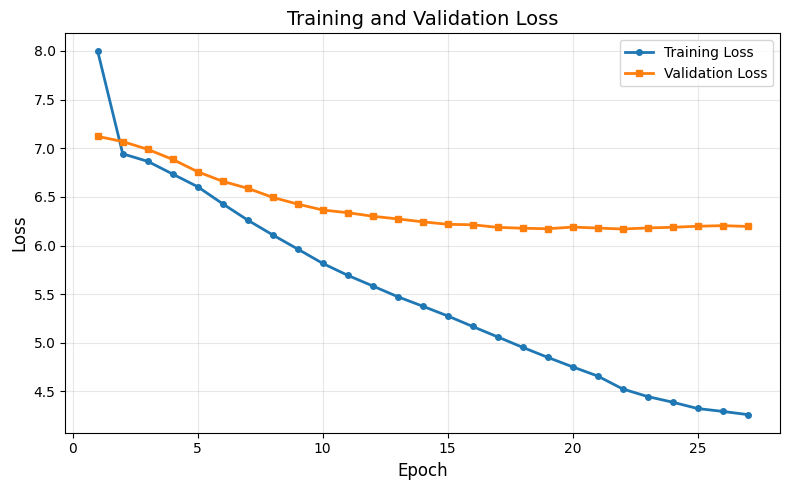

Figure saved successfully.


In [ ]:
# ============================================================
# CELL 21: TRAINING AND VALIDATION LOSS
# ============================================================

import pickle
import matplotlib.pyplot as plt
import os

RESULT_FOLDER = "/content/drive/MyDrive/PhD/HLSTM-GRU"

HISTORY_PATH = f"{RESULT_FOLDER}/hlstm_gru_training_history.pkl"

with open(HISTORY_PATH, "rb") as f:
    history_data = pickle.load(f)

print("History type:", type(history_data))

# Handle Keras History object or dictionary
if hasattr(history_data, "history"):
    history = history_data.history
else:
    history = history_data

print("Available history keys:")
print(history.keys())

train_loss = history.get("loss")
val_loss = history.get("val_loss")

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_loss,
    marker="o",
    linewidth=2,
    markersize=4,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    marker="s",
    linewidth=2,
    markersize=4,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Training and Validation Loss", fontsize=14)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save high-resolution versions
plt.savefig(
    f"{RESULT_FOLDER}/figure_training_validation_loss.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/figure_training_validation_loss.pdf",
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully.")

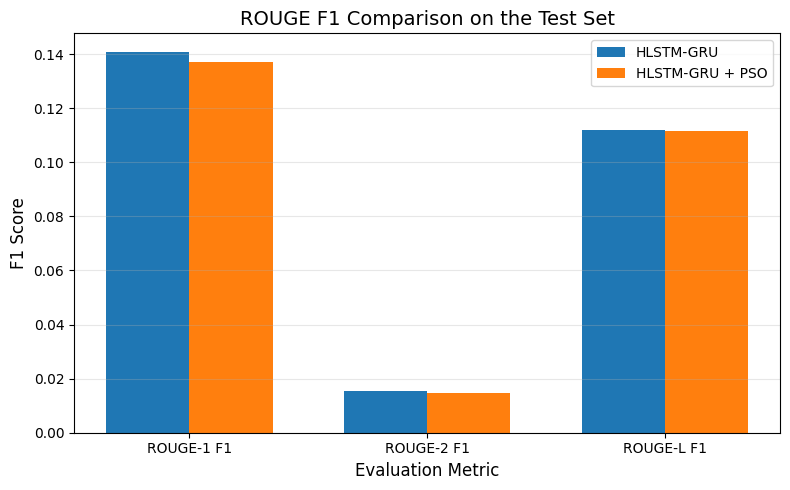

Figure saved successfully.


In [ ]:
# ============================================================
# CELL 22: ROUGE F1 COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "ROUGE-1 F1",
    "ROUGE-2 F1",
    "ROUGE-L F1"
]

baseline = [
    0.140622,
    0.015609,
    0.111769
]

pso = [
    0.137225,
    0.014748,
    0.111387
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    baseline,
    width,
    label="HLSTM-GRU"
)

plt.bar(
    x + width/2,
    pso,
    width,
    label="HLSTM-GRU + PSO"
)

plt.xticks(x, metrics)
plt.ylabel("F1 Score", fontsize=12)
plt.xlabel("Evaluation Metric", fontsize=12)
plt.title("ROUGE F1 Comparison on the Test Set", fontsize=14)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{RESULT_FOLDER}/figure_rouge_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/figure_rouge_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully.")

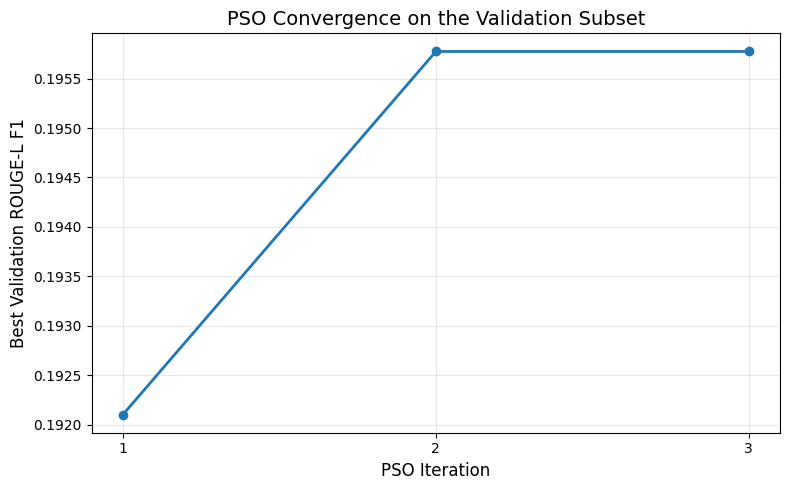

PSO fitness history:
Iteration 1: 0.192104
Iteration 2: 0.195773
Iteration 3: 0.195773
Figure saved successfully.


In [ ]:
# ============================================================
# CELL 23: PSO CONVERGENCE CURVE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

PSO_HISTORY_PATH = f"{RESULT_FOLDER}/pso_fitness_history.npy"

fitness_history = np.load(PSO_HISTORY_PATH)

iterations = np.arange(1, len(fitness_history) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    iterations,
    fitness_history,
    marker="o",
    linewidth=2,
    markersize=6
)

plt.xlabel("PSO Iteration", fontsize=12)
plt.ylabel("Best Validation ROUGE-L F1", fontsize=12)
plt.title("PSO Convergence on the Validation Subset", fontsize=14)

plt.xticks(iterations)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{RESULT_FOLDER}/figure_pso_convergence.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/figure_pso_convergence.pdf",
    bbox_inches="tight"
)

plt.show()

print("PSO fitness history:")
for i, score in enumerate(fitness_history, start=1):
    print(f"Iteration {i}: {score:.6f}")

print("Figure saved successfully.")

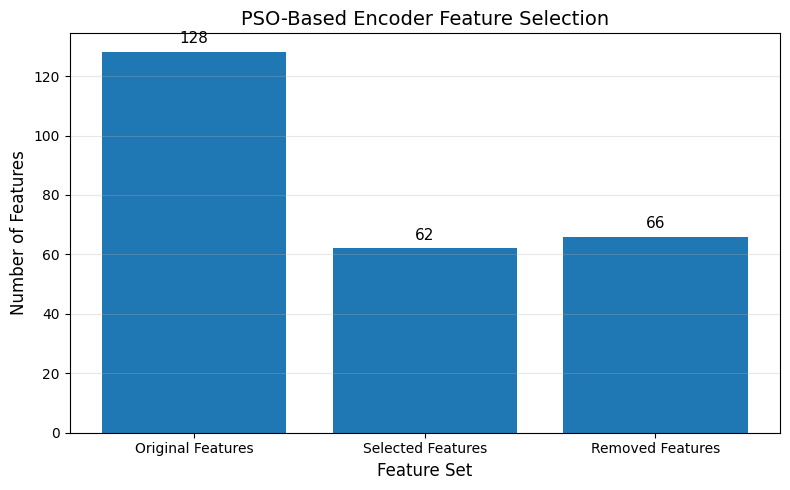

Original features : 128
Selected features : 62
Removed features  : 66
Feature reduction : 51.56%
Figure saved successfully.


In [ ]:
# ============================================================
# CELL 24: FEATURE SELECTION / DIMENSIONALITY REDUCTION
# ============================================================

import matplotlib.pyplot as plt

original_features = 128
selected_features = 62
removed_features = original_features - selected_features

labels = [
    "Original Features",
    "Selected Features",
    "Removed Features"
]

values = [
    original_features,
    selected_features,
    removed_features
]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.ylabel("Number of Features", fontsize=12)
plt.xlabel("Feature Set", fontsize=12)
plt.title("PSO-Based Encoder Feature Selection", fontsize=14)

plt.grid(axis="y", alpha=0.3)

# Add values above bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        str(value),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()

plt.savefig(
    f"{RESULT_FOLDER}/figure_feature_selection.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/figure_feature_selection.pdf",
    bbox_inches="tight"
)

plt.show()

print("Original features :", original_features)
print("Selected features :", selected_features)
print("Removed features  :", removed_features)
print(
    "Feature reduction :",
    f"{(removed_features/original_features)*100:.2f}%"
)

print("Figure saved successfully.")

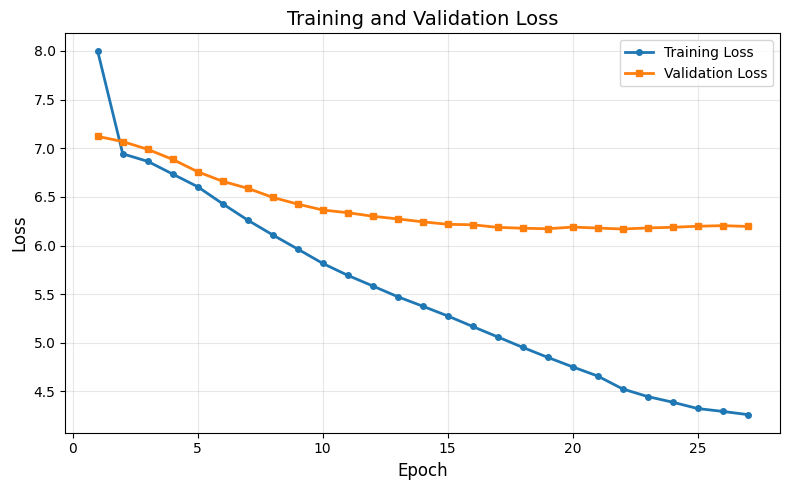

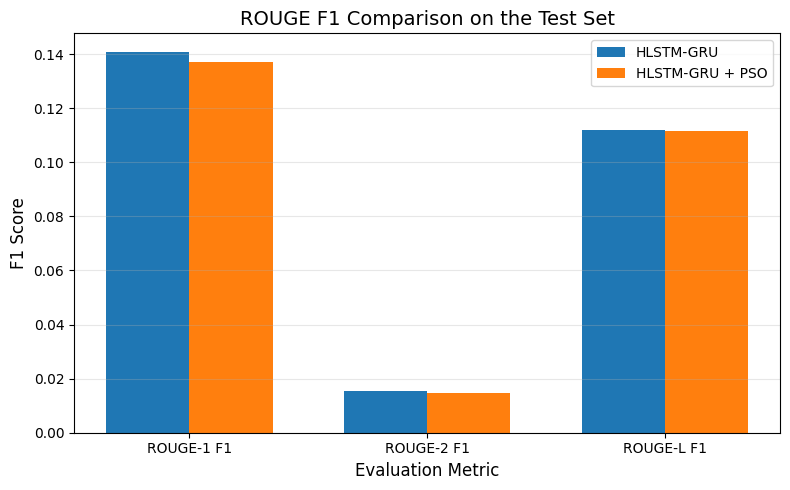

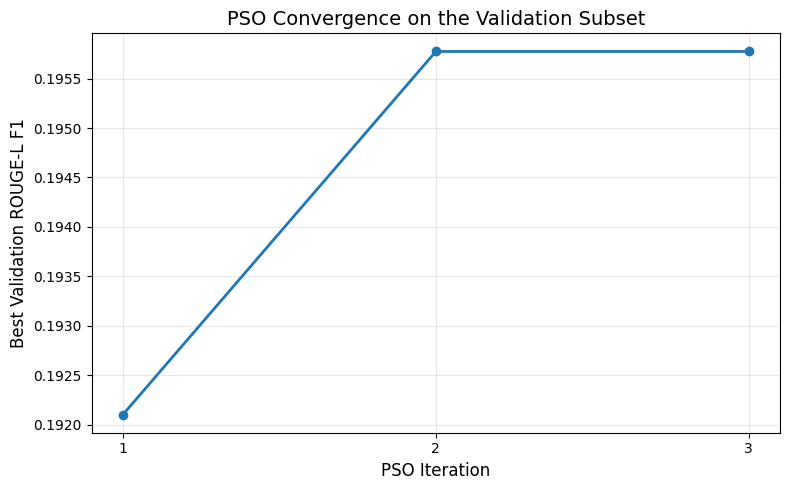

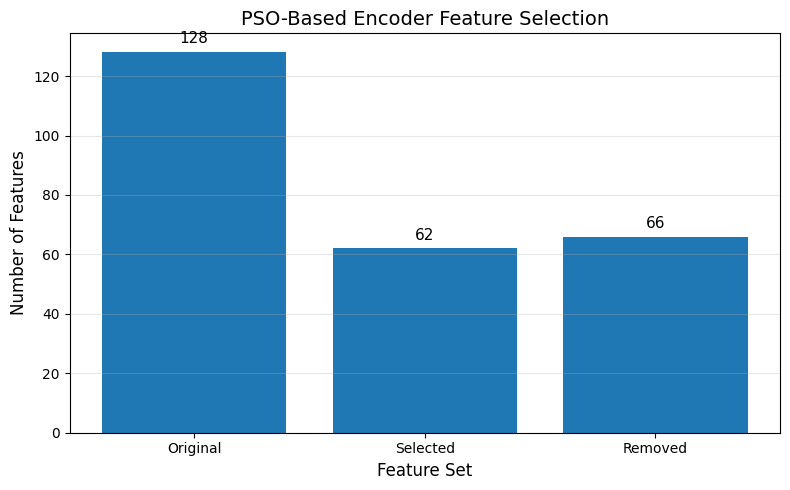


ALL FIGURES GENERATED SUCCESSFULLY

Saved in:
/content/drive/MyDrive/PhD/HLSTM-GRU

Files generated:
✓ Figure_Training_Validation_Loss.png
✓ Figure_Training_Validation_Loss.pdf
✓ Figure_ROUGE_Comparison.png
✓ Figure_ROUGE_Comparison.pdf
✓ Figure_PSO_Convergence.png
✓ Figure_PSO_Convergence.pdf
✓ Figure_Feature_Selection.png
✓ Figure_Feature_Selection.pdf

Feature reduction:
128 → 62 features
Reduction = 51.56%

PSO convergence:
Iteration 1: 0.192104
Iteration 2: 0.195773
Iteration 3: 0.195773



In [ ]:
# ============================================================
# FINAL FIGURE GENERATION CELL
# Generates 4 publication-quality figures
# ============================================================

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Folder
# ------------------------------------------------------------

RESULT_FOLDER = "/content/drive/MyDrive/PhD/HLSTM-GRU"

os.makedirs(RESULT_FOLDER, exist_ok=True)

# ============================================================
# FIGURE 1: TRAINING AND VALIDATION LOSS
# ============================================================

HISTORY_PATH = f"{RESULT_FOLDER}/hlstm_gru_training_history.pkl"

with open(HISTORY_PATH, "rb") as f:
    history_data = pickle.load(f)

if hasattr(history_data, "history"):
    history = history_data.history
else:
    history = history_data

train_loss = history["loss"]
val_loss = history["val_loss"]

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_loss,
    marker="o",
    linewidth=2,
    markersize=4,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    marker="s",
    linewidth=2,
    markersize=4,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Training and Validation Loss", fontsize=14)

plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{RESULT_FOLDER}/Figure_Training_Validation_Loss.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/Figure_Training_Validation_Loss.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 2: ROUGE F1 COMPARISON
# ============================================================

metrics = [
    "ROUGE-1 F1",
    "ROUGE-2 F1",
    "ROUGE-L F1"
]

baseline = [
    0.140622,
    0.015609,
    0.111769
]

pso = [
    0.137225,
    0.014748,
    0.111387
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    baseline,
    width,
    label="HLSTM-GRU"
)

plt.bar(
    x + width/2,
    pso,
    width,
    label="HLSTM-GRU + PSO"
)

plt.xticks(x, metrics)
plt.xlabel("Evaluation Metric", fontsize=12)
plt.ylabel("F1 Score", fontsize=12)
plt.title("ROUGE F1 Comparison on the Test Set", fontsize=14)

plt.legend(fontsize=10)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{RESULT_FOLDER}/Figure_ROUGE_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/Figure_ROUGE_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 3: PSO CONVERGENCE
# ============================================================

PSO_HISTORY_PATH = f"{RESULT_FOLDER}/pso_fitness_history.npy"

fitness_history = np.load(PSO_HISTORY_PATH)

iterations = np.arange(1, len(fitness_history) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    iterations,
    fitness_history,
    marker="o",
    linewidth=2,
    markersize=6
)

plt.xlabel("PSO Iteration", fontsize=12)
plt.ylabel("Best Validation ROUGE-L F1", fontsize=12)
plt.title("PSO Convergence on the Validation Subset", fontsize=14)

plt.xticks(iterations)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{RESULT_FOLDER}/Figure_PSO_Convergence.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/Figure_PSO_Convergence.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 4: FEATURE SELECTION
# ============================================================

original_features = 128
selected_features = 62
removed_features = original_features - selected_features

labels = [
    "Original",
    "Selected",
    "Removed"
]

values = [
    original_features,
    selected_features,
    removed_features
]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.xlabel("Feature Set", fontsize=12)
plt.ylabel("Number of Features", fontsize=12)
plt.title("PSO-Based Encoder Feature Selection", fontsize=14)

plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        str(value),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()

plt.savefig(
    f"{RESULT_FOLDER}/Figure_Feature_Selection.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{RESULT_FOLDER}/Figure_Feature_Selection.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "="*60)
print("ALL FIGURES GENERATED SUCCESSFULLY")
print("="*60)

print("\nSaved in:")
print(RESULT_FOLDER)

print("\nFiles generated:")

files = [
    "Figure_Training_Validation_Loss.png",
    "Figure_Training_Validation_Loss.pdf",
    "Figure_ROUGE_Comparison.png",
    "Figure_ROUGE_Comparison.pdf",
    "Figure_PSO_Convergence.png",
    "Figure_PSO_Convergence.pdf",
    "Figure_Feature_Selection.png",
    "Figure_Feature_Selection.pdf"
]

for f in files:
    print("✓", f)

print("\nFeature reduction:")
print(f"128 → 62 features")
print(f"Reduction = {removed_features/original_features*100:.2f}%")

print("\nPSO convergence:")
for i, score in enumerate(fitness_history, 1):
    print(f"Iteration {i}: {score:.6f}")

print("\n" + "="*60)

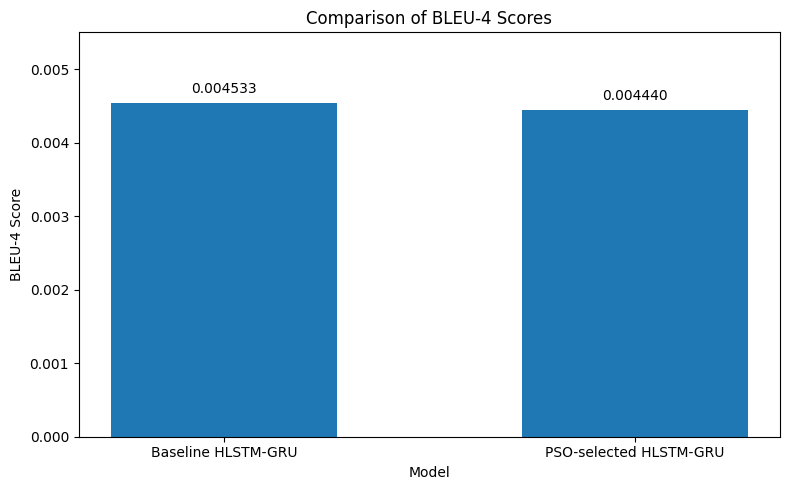

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# BLEU-4 COMPARISON
# ============================================================

models = [
    "Baseline HLSTM-GRU",
    "PSO-selected HLSTM-GRU"
]

bleu_scores = [
    0.004533,
    0.004440
]

x = np.arange(len(models))

plt.figure(figsize=(8, 5))

bars = plt.bar(x, bleu_scores, width=0.55)

plt.ylabel("BLEU-4 Score")
plt.xlabel("Model")
plt.title("Comparison of BLEU-4 Scores")

plt.xticks(x, models, rotation=0)
plt.ylim(0, 0.0055)

# Display exact values above bars
for bar, score in zip(bars, bleu_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.0001,
        f"{score:.6f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "/content/bleu_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [47]:
# ===== RESUME: load saved summaries instead of regenerating =====
import pickle
OUT = "/content/drive/MyDrive/PhD/HLSTM-GRU/revision_results"
outputs = pickle.load(open(f"{OUT}/all_summaries.pkl", "rb"))
baseline_test_summaries = outputs["baseline"]
pso_test_summaries = outputs["pso"]
if "t5" in outputs:
    t5_test_summaries = outputs["t5"]
print("Loaded:", list(outputs.keys()), "| docs:", len(baseline_test_summaries))

Loaded: ['baseline', 'pso', 'Lead-3', 'Lead-171 words', 'TextRank', 'LexRank', 't5'] | docs: 223


# ===== REVISION EXPERIMENTS (Scientific Reports, major revision) =====
Run these cells **after** the original notebook above, in the same Colab runtime
(they reuse `train_df`, `val_df`, `test_df`, `model`, `encoder_model`, `idx2word`,
`generate_autoregressive_summary`, `baseline_test_summaries`, `pso_test_summaries`,
`gbest_mask`, `encoder_sequence_val`, `encoder_state_val`, `decoder_val_hg`, `X_val_hg`,
`decoder_embedding_layer`, `decoder_gru_layer`, `attention_layer`, `concat_layer`, `output_layer`).

| Section | Reviewer point |
|---|---|
| R0 Dataset statistics & reference extractiveness | R3-8, R1 minor 8 |
| R1 Fixed, documented evaluation (ROUGE + BLEU, versions, CIs) | R1-M3, R1 minor 6 & 9 |
| R2 Extractive baselines (Lead-3, Lead-N, TextRank, LexRank) | R1-M2, R1-M6 |
| R3 Neural baseline: fine-tuned T5-small, same split | R1-M6 |
| R4 PSO controls: all-features mask, random masks, stronger multi-seed PSO | R1-M4, R1-M5 |
| R5 Genuinely smaller retrained model (params + latency) | R1-M4 |
| R6 Qualitative examples + repetition statistics | R1 minor 5 |
| R7 Export all tables | — |

## R0 — Dataset statistics and how the reference summaries were created (R3-8)

In [48]:
import re, numpy as np, pandas as pd

def fix_glued_sentences(text):
    # BBC summaries concatenate sentences without a space: "Idiot.Goodrem" -> "Idiot. Goodrem"
    return re.sub(r'([.!?]["\']?)(?=[A-Z"\'])', r'\1 ', str(text))

def split_sentences(text):
    text = fix_glued_sentences(text)
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+(?=[A-Z"\'])', text) if s.strip()]

def wc(t):
    return len(str(t).split())

stats = df.copy()
stats["summary_fixed"] = stats["summary"].apply(fix_glued_sentences)
stats["art_words"] = stats["article"].apply(wc)
stats["sum_words"] = stats["summary_fixed"].apply(wc)
stats["art_sents"] = stats["article"].apply(lambda t: len(split_sentences(t)))
stats["sum_sents"] = stats["summary_fixed"].apply(lambda t: len(split_sentences(t)))

def extractive_fraction(row):
    """Share of reference-summary sentences that occur verbatim in the article."""
    art = re.sub(r"\s+", " ", row["article"])
    sents = split_sentences(row["summary"])
    if not sents:
        return np.nan
    return np.mean([re.sub(r"\s+", " ", s) in art for s in sents])

stats["extractive_frac"] = stats.apply(extractive_fraction, axis=1)

# tokens as seen by the model (same regex tokenizer)
stats["art_tokens"] = stats["article"].apply(lambda t: len(tokenize(t)))
stats["sum_tokens"] = stats["summary"].apply(lambda t: len(tokenize(t)))

per_cat = stats.groupby("category").agg(
    n=("article", "size"),
    article_words_mean=("art_words", "mean"),
    summary_words_mean=("sum_words", "mean"),
    article_sents_mean=("art_sents", "mean"),
    summary_sents_mean=("sum_sents", "mean"),
    extractive_frac_mean=("extractive_frac", "mean"),
).round(2)
overall = stats[["art_words", "sum_words", "art_sents", "sum_sents", "extractive_frac"]].mean().round(3)

split_counts = pd.DataFrame({
    "train": train_df["category"].value_counts(),
    "val": val_df["category"].value_counts(),
    "test": test_df["category"].value_counts(),
})
print(per_cat.to_string()); print("\nOverall means:\n", overall.to_string())
print("\nCategory counts per split:\n", split_counts.to_string())
print(f"\nArticles longer than {MAX_ARTICLE_LEN} tokens (truncated): "
      f"{(stats.art_tokens > MAX_ARTICLE_LEN).mean()*100:.1f}%")
print(f"Summaries longer than {MAX_SUMMARY_LEN-2} tokens (truncated): "
      f"{(stats.sum_tokens > MAX_SUMMARY_LEN-2).mean()*100:.1f}%")
print("Mean reference length in tokens:", round(stats.sum_tokens.mean(), 1))

                 n  article_words_mean  summary_words_mean  article_sents_mean  summary_sents_mean  extractive_frac_mean
category                                                                                                                
business       510              328.88              145.62               15.78                6.70                  0.91
entertainment  386              330.62              149.95               16.35                6.93                  0.89
politics       417              453.97              203.53               21.12                8.84                  0.86
sport          511              329.26              149.44               17.33                7.26                  0.74
tech           401              502.69              222.84               24.19               10.02                  0.89

Overall means:
 art_words          384.039
sum_words          172.018
art_sents           18.752
sum_sents            7.870
extractive_frac      0.856



## R1 — One documented evaluation function (R1-M3, minor 6, minor 9)
* ROUGE: `rouge-score`, stemming on, no stop-word removal, mean of per-document F1.
* BLEU is reported **two ways**, both with identical tokenization on both sides:
  1. SacreBLEU corpus BLEU-4 (13a tokenizer, lowercased) — the standard, citable value (report its signature);
  2. NLTK corpus BLEU-4, method1 smoothing, using the *same regex tokenizer as the model*.
* The original notebook mixed `.split()` on raw references (punctuation glued to words, e.g. `"strategy.Mr"`)
  with space-separated generated tokens (`"the us ,"`). This tokenization mismatch alone deflates BLEU and is
  very likely what Reviewer 1 suspected. It also produced two different numbers in your notebook
  (cell 18 corpus BLEU = 0.0029 vs cell 44 averaged sentence BLEU = 0.004533).
* 95% bootstrap CIs and a paired test between systems are added.

In [49]:
!pip install -q rouge-score nltk sacrebleu

import importlib.metadata as im
import sacrebleu, nltk
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from scipy.stats import wilcoxon

EVAL_VERSIONS = {p: im.version(p) for p in ["rouge-score", "nltk", "sacrebleu"]}
print(EVAL_VERSIONS)

_rs = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
_smooth = SmoothingFunction().method1
REFS_TEST = [fix_glued_sentences(s) for s in test_df["summary"].astype(str).tolist()]

def per_doc_rouge(refs, hyps):
    out = {"rouge1": [], "rouge2": [], "rougeL": []}
    for r, h in zip(refs, hyps):
        s = _rs.score(r, h)
        for k in out:
            out[k].append(s[k].fmeasure)
    return {k: np.array(v) for k, v in out.items()}

def bootstrap_ci(x, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    means = [rng.choice(x, size=len(x), replace=True).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

def evaluate_system(name, hyps, refs=REFS_TEST):
    hyps = [str(h) for h in hyps]
    r = per_doc_rouge(refs, hyps)
    sb = sacrebleu.corpus_bleu(hyps, [refs], lowercase=True, tokenize="13a")
    nltk_bleu = corpus_bleu([[tokenize(x)] for x in refs], [tokenize(h) for h in hyps],
                            weights=(0.25,) * 4, smoothing_function=_smooth)
    hyp_len = np.mean([len(tokenize(h)) for h in hyps])
    ref_len = np.mean([len(tokenize(x)) for x in refs])
    row = {"system": name}
    for k in ["rouge1", "rouge2", "rougeL"]:
        lo, hi = bootstrap_ci(r[k])
        row[f"{k}_F1"] = r[k].mean(); row[f"{k}_CI95"] = f"[{lo:.4f}, {hi:.4f}]"
    row.update({"BLEU4_sacrebleu": sb.score / 100, "BLEU4_nltk_corpus": nltk_bleu,
                "BP_sacrebleu": sb.bp, "avg_hyp_tokens": hyp_len, "avg_ref_tokens": ref_len})
    return row, r, sb

RESULTS, PERDOC = [], {}
def add_result(name, hyps):
    row, r, sb = evaluate_system(name, hyps)
    RESULTS.append(row); PERDOC[name] = r
    print(f"{name:28s} R1={row['rouge1_F1']:.4f} R2={row['rouge2_F1']:.4f} RL={row['rougeL_F1']:.4f} "
          f"BLEU(sacre)={row['BLEU4_sacrebleu']:.4f} BLEU(nltk)={row['BLEU4_nltk_corpus']:.4f} "
          f"BP={row['BP_sacrebleu']:.3f} len={row['avg_hyp_tokens']:.0f}/{row['avg_ref_tokens']:.0f}")
    return row

add_result("HLSTM-GRU (baseline)", baseline_test_summaries)
add_result("HLSTM-GRU + PSO mask", pso_test_summaries)

# SacreBLEU signature (needs one scored call first)
_bleu_metric = sacrebleu.metrics.BLEU(lowercase=True, tokenize="13a")
_bleu_metric.corpus_score(baseline_test_summaries, [REFS_TEST])
SACREBLEU_SIGNATURE = str(_bleu_metric.get_signature())
print("\nSacreBLEU signature:", SACREBLEU_SIGNATURE)

# Paired significance test: baseline vs PSO
stat, p = wilcoxon(PERDOC["HLSTM-GRU (baseline)"]["rougeL"], PERDOC["HLSTM-GRU + PSO mask"]["rougeL"])
print(f"Wilcoxon signed-rank, ROUGE-L baseline vs PSO: W={stat:.1f}, p={p:.4f}")

# Show the confidence intervals
print("\n95% bootstrap confidence intervals:")
for row in RESULTS:
    print(f"{row['system']:28s} R1 {row['rouge1_CI95']}  R2 {row['rouge2_CI95']}  RL {row['rougeL_CI95']}")

{'rouge-score': '0.1.2', 'nltk': '3.9.1', 'sacrebleu': '2.6.0'}
HLSTM-GRU (baseline)         R1=0.1406 R2=0.0156 RL=0.1118 BLEU(sacre)=0.0036 BLEU(nltk)=0.0060 BP=0.519 len=120/208
HLSTM-GRU + PSO mask         R1=0.1372 R2=0.0147 RL=0.1114 BLEU(sacre)=0.0034 BLEU(nltk)=0.0048 BP=0.519 len=120/208

SacreBLEU signature: nrefs:1|case:lc|eff:no|tok:13a|smooth:exp|version:2.6.0
Wilcoxon signed-rank, ROUGE-L baseline vs PSO: W=11282.0, p=0.5565

95% bootstrap confidence intervals:
HLSTM-GRU (baseline)         R1 [0.1341, 0.1474]  R2 [0.0137, 0.0176]  RL [0.1064, 0.1170]
HLSTM-GRU + PSO mask         R1 [0.1311, 0.1432]  R2 [0.0129, 0.0167]  RL [0.1060, 0.1164]


## R2 — Extractive baselines on the identical test split (R1-M2, R1-M6)
Lead-3, Lead-N (first N words, N = mean reference length), TextRank (TF-IDF cosine graph + PageRank) and
LexRank (thresholded cosine graph + PageRank), each selecting sentences up to the mean reference length.
**Expect these to score far higher than the neural model**, because BBC reference summaries are themselves
extracted article sentences (see R0). Report that honestly — it is what the reviewer is asking for.

In [50]:
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

TARGET_WORDS = int(round(np.mean([len(s.split()) for s in train_df["summary"].apply(fix_glued_sentences)])))
print("Length budget (mean train reference words):", TARGET_WORDS)

def take_until_budget(sentences_in_order, budget=TARGET_WORDS):
    out, n = [], 0
    for s in sentences_in_order:
        if n >= budget:
            break
        out.append(s); n += len(s.split())
    return " ".join(out)

def lead_k(article, k=3):
    return " ".join(split_sentences(article)[:k])

def lead_n_words(article, budget=TARGET_WORDS):
    return take_until_budget(split_sentences(article), budget)

def graph_rank_summary(article, mode="textrank", threshold=0.1, budget=TARGET_WORDS):
    sents = split_sentences(article)
    if len(sents) <= 2:
        return " ".join(sents)
    tfidf = TfidfVectorizer(stop_words="english").fit_transform(sents)
    sim = cosine_similarity(tfidf)
    np.fill_diagonal(sim, 0.0)
    if mode == "lexrank":
        sim = (sim > threshold).astype(float)
    scores = nx.pagerank(nx.from_numpy_array(sim), max_iter=500)
    ranked = sorted(range(len(sents)), key=lambda i: -scores[i])
    chosen, n = [], 0
    for i in ranked:
        if n >= budget:
            break
        chosen.append(i); n += len(sents[i].split())
    return " ".join(sents[i] for i in sorted(chosen))  # keep article order

articles_test = test_df["article"].astype(str).tolist()
BASELINE_OUTPUTS = {
    "Lead-3": [lead_k(a, 3) for a in articles_test],
    f"Lead-{TARGET_WORDS} words": [lead_n_words(a) for a in articles_test],
    "TextRank": [graph_rank_summary(a, "textrank") for a in articles_test],
    "LexRank": [graph_rank_summary(a, "lexrank") for a in articles_test],
}
for name, hyps in BASELINE_OUTPUTS.items():
    add_result(name, hyps)

Length budget (mean train reference words): 171
Lead-3                       R1=0.4553 R2=0.3534 RL=0.3515 BLEU(sacre)=0.1090 BLEU(nltk)=0.1144 BP=0.183 len=78/208
Lead-171 words               R1=0.6245 R2=0.5133 RL=0.3913 BLEU(sacre)=0.4957 BLEU(nltk)=0.4975 BP=1.000 len=215/208
TextRank                     R1=0.7484 R2=0.6995 RL=0.4701 BLEU(sacre)=0.6792 BLEU(nltk)=0.6778 BP=1.000 len=217/208
LexRank                      R1=0.7139 R2=0.6461 RL=0.4448 BLEU(sacre)=0.6284 BLEU(nltk)=0.6282 BP=1.000 len=218/208


## R3 — Neural baseline: T5-small fine-tuned on the same 1,780 training articles (R1-M6)
Plain PyTorch loop (no Trainer API, so it is robust to `transformers` version changes).
On a Colab T4 this takes roughly 15–25 min. Validation loss selects the best epoch; test is touched once.

In [ ]:
!pip install -q transformers sentencepiece

import torch, time, random, copy as _copy
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

T5_NAME, T5_SEED = "t5-small", 42
T5_MAX_IN, T5_MAX_OUT, T5_EPOCHS, T5_BS, T5_LR = 512, 256, 8, 8, 3e-4
random.seed(T5_SEED); np.random.seed(T5_SEED); torch.manual_seed(T5_SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

t5_tok = AutoTokenizer.from_pretrained(T5_NAME)
t5 = AutoModelForSeq2SeqLM.from_pretrained(T5_NAME).to(device)

def t5_batches(frame, shuffle):
    idx = np.arange(len(frame))
    if shuffle:
        np.random.shuffle(idx)
    for i in range(0, len(idx), T5_BS):
        b = frame.iloc[idx[i:i + T5_BS]]
        enc = t5_tok(["summarize: " + a for a in b["article"]], max_length=T5_MAX_IN,
                     truncation=True, padding=True, return_tensors="pt")
        lab = t5_tok(list(b["summary"].apply(fix_glued_sentences)), max_length=T5_MAX_OUT,
                     truncation=True, padding=True, return_tensors="pt").input_ids
        lab[lab == t5_tok.pad_token_id] = -100
        yield enc.to(device), lab.to(device)

opt = torch.optim.AdamW(t5.parameters(), lr=T5_LR)
best_val, best_state, t5_hist = 1e9, None, []
t0 = time.time()
for ep in range(T5_EPOCHS):
    t5.train(); tr = []
    for enc, lab in t5_batches(train_df, True):
        loss = t5(**enc, labels=lab).loss
        loss.backward(); opt.step(); opt.zero_grad(); tr.append(loss.item())
    t5.eval(); va = []
    with torch.no_grad():
        for enc, lab in t5_batches(val_df, False):
            va.append(t5(**enc, labels=lab).loss.item())
    t5_hist.append((ep + 1, np.mean(tr), np.mean(va)))
    print(f"epoch {ep+1}: train {np.mean(tr):.4f}  val {np.mean(va):.4f}")
    if np.mean(va) < best_val:
        best_val, best_state = np.mean(va), _copy.deepcopy(t5.state_dict())
t5.load_state_dict(best_state)
print(f"T5 training time: {(time.time()-t0)/60:.1f} min, params: {sum(p.numel() for p in t5.parameters()):,}")

def t5_generate(texts, num_beams=4, bs=16):
    out = []
    t5.eval()
    for i in range(0, len(texts), bs):
        enc = t5_tok(["summarize: " + a for a in texts[i:i + bs]], max_length=T5_MAX_IN,
                     truncation=True, padding=True, return_tensors="pt").to(device)
        with torch.no_grad():
            g = t5.generate(**enc, max_length=T5_MAX_OUT, num_beams=num_beams,
                            no_repeat_ngram_size=3, early_stopping=True)
        out += t5_tok.batch_decode(g, skip_special_tokens=True)
    return out

t5_test_summaries = t5_generate(articles_test)
add_result("T5-small (fine-tuned)", t5_test_summaries)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

epoch 1: train 0.9295  val 0.7725
epoch 2: train 0.7008  val 0.7313
epoch 3: train 0.6484  val 0.7091
epoch 4: train 0.6123  val 0.6955
epoch 5: train 0.5803  val 0.6823
epoch 6: train 0.5547  val 0.6908
epoch 7: train 0.5285  val 0.6934
epoch 8: train 0.5064  val 0.6867
T5 training time: 15.3 min, params: 60,506,624
T5-small (fine-tuned)        R1=0.6041 R2=0.5222 RL=0.4409 BLEU(sacre)=0.2849 BLEU(nltk)=0.2871 BP=0.395 len=108/208


{'system': 'T5-small (fine-tuned)',
 'rouge1_F1': np.float64(0.6041403668463071),
 'rouge1_CI95': '[0.5817, 0.6226]',
 'rouge2_F1': np.float64(0.5222011733430206),
 'rouge2_CI95': '[0.4974, 0.5439]',
 'rougeL_F1': np.float64(0.44088979160835),
 'rougeL_CI95': '[0.4233, 0.4586]',
 'BLEU4_sacrebleu': 0.2848802443585814,
 'BLEU4_nltk_corpus': 0.28705877327493845,
 'BP_sacrebleu': 0.395474114031224,
 'avg_hyp_tokens': np.float64(108.28699551569507),
 'avg_ref_tokens': np.float64(208.46188340807174)}

## R4 — PSO controls and a stronger PSO protocol (R1-M4, R1-M5)
1. **Sanity check**: fitness of the *all-128-features* mask on the same 20 validation samples. If it is ≥ 0.195773,
   PSO never beat "no masking" even on its own objective.
2. **Random-mask control**: 30 random masks with exactly 62 features, evaluated on the test set. If the PSO mask is
   inside the random distribution, the selection carries no information.
3. **Stronger search**: 100 validation samples, 30 particles × 20 iterations, 3 seeds, with an optional sparsity
   term. Fitness stays teacher-forced (fast, batched) — state this explicitly in the paper, because it is not the
   same as the autoregressive decoding used at test time.

In [ ]:
from rouge_score import rouge_scorer as _rsmod
_rsL = _rsmod.RougeScorer(["rougeL"], use_stemmer=True)
REFS_VAL = [fix_glued_sentences(s) for s in val_df["summary"].astype(str).tolist()]

def teacher_forced_fitness(mask, idx):
    mask = np.asarray(mask, dtype=np.float32).reshape(1, 1, -1)
    enc = tf.constant(encoder_sequence_val[idx] * mask)
    emb = decoder_embedding_layer(tf.constant(decoder_val_hg[idx]))
    dec_out, _ = decoder_gru_layer(emb, initial_state=tf.constant(encoder_state_val[idx]))
    ctx = concat_layer([dec_out, attention_layer([dec_out, enc])])
    preds = output_layer(ctx).numpy()
    hyps = predictions_to_summaries(preds)
    return float(np.mean([_rsL.score(REFS_VAL[i], h)["rougeL"].fmeasure for i, h in zip(idx, hyps)]))

# --- 1. sanity check on the ORIGINAL 20 PSO samples
all_ones = np.ones(128, dtype=np.float32)
f_all = teacher_forced_fitness(all_ones, pso_indices)
f_pso = teacher_forced_fitness(gbest_mask, pso_indices)
print(f"Fitness on original 20 PSO samples: all-128 = {f_all:.6f} | PSO-62 = {f_pso:.6f}")

Fitness on original 20 PSO samples: all-128 = 0.190462 | PSO-62 = 0.195773


In [ ]:
# --- 2. random-mask control on the TEST set (autoregressive, ~4 s/doc/mask -> use a 60-doc subset)
N_RANDOM, K_FEAT, SUBSET = 30, int(gbest_mask.sum()), 60
rng_ctrl = np.random.default_rng(123)
subset = np.sort(rng_ctrl.choice(len(test_df), SUBSET, replace=False))
refs_sub = [REFS_TEST[i] for i in subset]

def autoreg_rougeL(mask, idxs):
    hyps = [generate_autoregressive_summary(encoder_sequence_test[i:i+1], encoder_state_test[i:i+1],
                                            feature_mask=mask, max_length=MAX_SUMMARY_LEN) for i in idxs]
    return per_doc_rouge([REFS_TEST[i] for i in idxs], hyps)["rougeL"].mean()

ctrl = {"all_128": autoreg_rougeL(None, subset), "pso_62": autoreg_rougeL(gbest_mask, subset)}
random_scores = []
for r in range(N_RANDOM):
    m = np.zeros(128, dtype=np.float32); m[rng_ctrl.choice(128, K_FEAT, replace=False)] = 1
    random_scores.append(autoreg_rougeL(m, subset))
    print(f"random mask {r+1}/{N_RANDOM}: {random_scores[-1]:.4f}")
random_scores = np.array(random_scores)
pct = (random_scores < ctrl["pso_62"]).mean() * 100
print(f"\nTest subset ({SUBSET} docs) ROUGE-L: all-128={ctrl['all_128']:.4f}, PSO-62={ctrl['pso_62']:.4f}, "
      f"random-62 mean={random_scores.mean():.4f} ± {random_scores.std():.4f} "
      f"(PSO beats {pct:.0f}% of random masks)")

random mask 1/30: 0.1078
random mask 2/30: 0.1093
random mask 3/30: 0.1082
random mask 4/30: 0.1186
random mask 5/30: 0.0979
random mask 6/30: 0.1167
random mask 7/30: 0.1114
random mask 8/30: 0.1138
random mask 9/30: 0.1060
random mask 10/30: 0.1100
random mask 11/30: 0.1132
random mask 12/30: 0.1065
random mask 13/30: 0.1119
random mask 14/30: 0.1083
random mask 15/30: 0.1167
random mask 16/30: 0.1136
random mask 17/30: 0.1151
random mask 18/30: 0.1102
random mask 19/30: 0.1044
random mask 20/30: 0.1071
random mask 21/30: 0.1107
random mask 22/30: 0.1174
random mask 23/30: 0.1058
random mask 24/30: 0.1091
random mask 25/30: 0.1085
random mask 26/30: 0.1004
random mask 27/30: 0.1179
random mask 28/30: 0.1145
random mask 29/30: 0.1073
random mask 30/30: 0.1125

Test subset (60 docs) ROUGE-L: all-128=0.1109, PSO-62=0.1083, random-62 mean=0.1104 ± 0.0049 (PSO beats 33% of random masks)


In [ ]:
# --- 3. stronger, multi-seed PSO (teacher-forced fitness, batched -> fast)
def run_pso(seed, n_particles=30, n_iter=20, n_samples=100, lam=0.0, w=0.7, c1=1.5, c2=1.5):
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(X_val_hg), n_samples, replace=False))
    pos = rng.uniform(0, 1, (n_particles, 128)); vel = rng.uniform(-0.1, 0.1, (n_particles, 128))
    pbest, pbest_s = pos.copy(), np.full(n_particles, -np.inf)
    gbest, gbest_s, hist = None, -np.inf, []
    for it in range(n_iter):
        for p in range(n_particles):
            m = (pos[p] >= 0.5).astype(np.float32)
            if m.sum() == 0: m[np.argmax(pos[p])] = 1
            f = teacher_forced_fitness(m, idx) - lam * m.mean()
            if f > pbest_s[p]: pbest_s[p], pbest[p] = f, pos[p].copy()
            if f > gbest_s: gbest_s, gbest = f, pos[p].copy()
        hist.append(gbest_s)
        r1, r2 = rng.random((n_particles, 128)), rng.random((n_particles, 128))
        vel = w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (gbest - pos)
        pos = np.clip(pos + vel, 0, 1)
        print(f"seed {seed} iter {it+1}/{n_iter}: best fitness {gbest_s:.5f}, "
              f"features {(gbest >= 0.5).sum()}")
    mask = (gbest >= 0.5).astype(np.float32)
    return {"seed": seed, "mask": mask, "n_features": int(mask.sum()), "best_fitness": float(gbest_s),
            "history": hist, "all128_fitness": teacher_forced_fitness(np.ones(128), idx)}

PSO_RUNS = [run_pso(s, lam=0.0) for s in (1, 2, 3)]
pso_summary = pd.DataFrame([{k: v for k, v in r.items() if k not in ("mask", "history")} for r in PSO_RUNS])
print(pso_summary.to_string(index=False))
print("mean ± std features:", pso_summary.n_features.mean(), "±", pso_summary.n_features.std())

# Evaluate each run's mask on the full test set (autoregressive; ~15 min per mask)
for r in PSO_RUNS:
    hyps = [generate_autoregressive_summary(encoder_sequence_test[i:i+1], encoder_state_test[i:i+1],
                                            feature_mask=r["mask"], max_length=MAX_SUMMARY_LEN)
            for i in range(len(test_df))]
    add_result(f"HLSTM-GRU + PSO (20 it, seed {r['seed']}, {r['n_features']} f)", hyps)

seed 1 iter 1/20: best fitness 0.19013, features 69
seed 1 iter 2/20: best fitness 0.19151, features 70
seed 1 iter 3/20: best fitness 0.19320, features 69
seed 1 iter 4/20: best fitness 0.19320, features 69
seed 1 iter 5/20: best fitness 0.19337, features 69
seed 1 iter 6/20: best fitness 0.19337, features 69
seed 1 iter 7/20: best fitness 0.19337, features 69
seed 1 iter 8/20: best fitness 0.19361, features 72
seed 1 iter 9/20: best fitness 0.19361, features 72
seed 1 iter 10/20: best fitness 0.19361, features 72
seed 1 iter 11/20: best fitness 0.19361, features 72
seed 1 iter 12/20: best fitness 0.19361, features 72
seed 1 iter 13/20: best fitness 0.19361, features 72
seed 1 iter 14/20: best fitness 0.19361, features 72
seed 1 iter 15/20: best fitness 0.19361, features 72
seed 1 iter 16/20: best fitness 0.19361, features 72
seed 1 iter 17/20: best fitness 0.19388, features 71
seed 1 iter 18/20: best fitness 0.19388, features 71
seed 1 iter 19/20: best fitness 0.19388, features 71
se

KeyboardInterrupt: 

## R5 — A *genuinely* smaller model, retrained (R1-M4) — optional but makes the efficiency claim real
`build_hlstm_gru(units)` reproduces your architecture exactly (with `units=128` it has 26,325,424 parameters,
which verifies the reconstruction). Train a 64-unit model (≈ the 62 features PSO kept) with the same protocol and
report parameters, ROUGE/BLEU and measured decoding latency against the 128-unit model.
The same function with different seeds gives you the multi-seed baseline (mean ± std) the reviewers ask for.
Note: PAD positions are excluded from the loss via `sample_weight`; if your original training did not do this, say so.

In [ ]:
from tensorflow.keras import layers, Model as KModel, callbacks

def build_hlstm_gru(units=128, vocab=30000, emb=300, dropout=0.0):
    enc_in = layers.Input((MAX_ARTICLE_LEN,), name="encoder_inputs")
    dec_in = layers.Input((MAX_SUMMARY_LEN,), name="decoder_inputs")
    x = layers.Embedding(vocab, emb, name="enc_emb")(enc_in)
    x = layers.LSTM(units, return_sequences=True, dropout=dropout, name="lstm1")(x)
    x = layers.LSTM(units, return_sequences=True, dropout=dropout, name="lstm2")(x)
    enc_seq, enc_state = layers.GRU(units, return_sequences=True, return_state=True, name="gru_enc")(x)
    y = layers.Embedding(vocab, emb, name="dec_emb")(dec_in)
    dec_seq, _ = layers.GRU(units, return_sequences=True, return_state=True, dropout=dropout,
                            name="gru_dec")(y, initial_state=enc_state)
    att = layers.Attention(name="attention")([dec_seq, enc_seq])
    ctx = layers.Concatenate(name="context")([dec_seq, att])
    out = layers.Dense(vocab, activation="softmax", name="out")(ctx)
    return KModel([enc_in, dec_in], out)

assert build_hlstm_gru(128).count_params() == 26325424, "architecture mismatch"
print("Reconstruction verified: 26,325,424 parameters")

X_train_hg = prepare_articles(train_df["article"].values)
dec_train_hg, y_train_hg = prepare_summaries(train_df["summary"].values)

def train_variant(units, seed, dropout=0.0, max_epochs=50):
    tf.keras.utils.set_random_seed(seed)
    m = build_hlstm_gru(units, dropout=dropout)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
              weighted_metrics=["accuracy"])
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]
    h = m.fit([X_train_hg, dec_train_hg], y_train_hg, sample_weight=(y_train_hg != PAD_ID).astype("float32"),
              validation_data=([X_val_hg, decoder_val_hg], y_val_hg, (y_val_hg != PAD_ID).astype("float32")),
              batch_size=32, epochs=max_epochs, callbacks=cbs, verbose=2)
    return m, h.history

def greedy_decode(m, X, max_len=MAX_SUMMARY_LEN):
    """Batched greedy decoding by re-running the full decoder (simple, model-agnostic)."""
    dec = np.zeros((len(X), MAX_SUMMARY_LEN), dtype="int32"); dec[:, 0] = START_ID
    done = np.zeros(len(X), bool)
    for t in range(max_len - 1):
        nxt = m.predict([X, dec], batch_size=64, verbose=0)[:, t, :].argmax(-1)
        nxt[done] = PAD_ID; dec[:, t + 1] = nxt; done |= nxt == END_ID
        if done.all(): break
    outs = []
    for row in dec[:, 1:]:
        toks = []
        for tid in row:
            if tid in (END_ID, PAD_ID): break
            w_ = idx2word.get(int(tid), "<UNK>")
            if w_ not in ("<UNK>", "<START>"): toks.append(w_)
        outs.append(" ".join(toks))
    return outs

VARIANTS = {}
for units in (128, 64):
    m, hist = train_variant(units, seed=42)
    t0 = time.time(); hyps = greedy_decode(m, X_test_hg); lat = (time.time() - t0) / len(X_test_hg)
    VARIANTS[units] = {"params": m.count_params(), "epochs_run": len(hist["loss"]),
                       "best_epoch": int(np.argmin(hist["val_loss"]) + 1), "sec_per_doc": lat}
    add_result(f"HLSTM-GRU retrained ({units} units)", hyps)
print(pd.DataFrame(VARIANTS).T)
# Multi-seed: repeat train_variant(128, seed) for seeds 1,2,3 and report mean ± std of ROUGE/BLEU.

## R6 — Qualitative examples and repetition statistics (R1 minor 5)

In [51]:
def repetition_rate(text, n=3):
    t = tokenize(text)
    grams = [tuple(t[i:i+n]) for i in range(len(t) - n + 1)]
    return 0.0 if not grams else 1 - len(set(grams)) / len(grams)

SYSTEM_OUTPUTS = {"HLSTM-GRU (baseline)": baseline_test_summaries, "HLSTM-GRU + PSO mask": pso_test_summaries,
                  "Lead-3": BASELINE_OUTPUTS["Lead-3"]}
if "t5_test_summaries" in globals():
    SYSTEM_OUTPUTS["T5-small (fine-tuned)"] = t5_test_summaries
rep = pd.DataFrame({k: {"repeated_trigram_rate": np.mean([repetition_rate(h) for h in v]),
                        "avg_tokens": np.mean([len(tokenize(h)) for h in v])} for k, v in SYSTEM_OUTPUTS.items()}).T
rep.loc["Reference"] = [np.mean([repetition_rate(r) for r in REFS_TEST]), np.mean([len(tokenize(r)) for r in REFS_TEST])]
print(rep.round(3).to_string())

# pick 3 examples: best, median and worst baseline ROUGE-L, one per different category if possible
rl = PERDOC["HLSTM-GRU (baseline)"]["rougeL"]
order = np.argsort(rl)
picks = [order[-1], order[len(order) // 2], order[0]]
examples = []
for i in picks:
    row = {"category": test_df["category"].iloc[i], "baseline_ROUGE_L": round(float(rl[i]), 4),
           "article (first 80 words)": " ".join(test_df["article"].iloc[i].split()[:80]) + " ...",
           "reference": REFS_TEST[i]}
    for k, v in SYSTEM_OUTPUTS.items():
        row[k] = v[i]
    examples.append(row)
examples_df = pd.DataFrame(examples)
for e in examples:
    print("\n" + "=" * 100)
    for k, v in e.items():
        print(f"[{k}] {v}\n")

                       repeated_trigram_rate  avg_tokens
HLSTM-GRU (baseline)                   0.755     119.901
HLSTM-GRU + PSO mask                   0.811     120.000
Lead-3                                 0.008      78.426
T5-small (fine-tuned)                  0.002     108.287
Reference                              0.028     208.462

[category] business

[baseline_ROUGE_L] 0.2418

[article (first 80 words)] Battered dollar hits another low The dollar has fallen to a new record low against the euro after data fuelled fresh concerns about the US economy. The greenback hit $1.3516 in thin New York trade, before rallying to $1.3509. The dollar has weakened sharply since September when it traded about $1.20, amid continuing worries over the levels of the US trade and budget deficits. Meanwhile, France's finance minister has said the world faced "economic catastrophe" unless the US worked with ...

[reference] The dollar has fallen to a new record low against the euro after data fuell

## R7 — Export all tables for the manuscript and the Zenodo deposit

In [54]:
import json, os
OUT = "/content/drive/MyDrive/PhD/HLSTM-GRU/revision_results"
os.makedirs(OUT, exist_ok=True)
results_df = pd.DataFrame(RESULTS)
results_df.to_csv(f"{OUT}/main_results.csv", index=False)
per_cat.to_csv(f"{OUT}/dataset_per_category.csv"); split_counts.to_csv(f"{OUT}/split_counts.csv")
rep.to_csv(f"{OUT}/repetition_length.csv"); examples_df.to_csv(f"{OUT}/qualitative_examples.csv", index=False)
if "pso_summary" in globals(): pso_summary.to_csv(f"{OUT}/pso_multiseed.csv", index=False)
json.dump({"eval_versions": EVAL_VERSIONS,
           "sacrebleu_signature": str(sacrebleu.metrics.BLEU(lowercase=True, tokenize="13a").get_signature()),
           "rouge": "rouge-score, use_stemmer=True, no stopword removal, mean of per-document F1",
           "bleu_nltk": "corpus_bleu, weights=(.25,.25,.25,.25), SmoothingFunction().method1, model regex tokenizer",
           "pso_sanity": {"all128_fitness_20": f_all, "pso62_fitness_20": f_pso} if "f_all" in globals() else None,
           "random_mask_control": {**ctrl, "random_mean": float(random_scores.mean()),
                                   "random_std": float(random_scores.std())} if "ctrl" in globals() else None},
          open(f"{OUT}/evaluation_config.json", "w"), indent=2, default=float)
cols = ["system", "rouge1_F1", "rouge2_F1", "rougeL_F1", "BLEU4_sacrebleu", "BLEU4_nltk_corpus", "avg_hyp_tokens"]
print(results_df[cols].round(4).to_string(index=False))
print("\nLaTeX:\n", results_df[cols].round(4).to_latex(index=False))

AttributeError: 'str' object has no attribute 'to_csv'

In [ ]:
# ===== R7: EXPORT ALL TABLES (fixed) =====
import json, os, pickle
import pandas as pd

OUT = "/content/drive/MyDrive/PhD/HLSTM-GRU/revision_results"
os.makedirs(OUT, exist_ok=True)

# Main results table
results_df = pd.DataFrame(RESULTS).drop_duplicates(subset="system", keep="last")
results_df.to_csv(f"{OUT}/main_results.csv", index=False)

# Other tables: save only if they exist AND are real tables
for name in ["per_cat", "split_counts", "rep", "pso_summary", "examples_df"]:
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(f"{OUT}/{name}.csv")
        print("saved", name)

# Evaluation configuration + PSO controls
config = {
    "eval_versions": globals().get("EVAL_VERSIONS"),
    "sacrebleu_signature": globals().get("SACREBLEU_SIGNATURE"),
    "rouge": "rouge-score, use_stemmer=True, no stopword removal, mean of per-document F1",
    "bleu_nltk": "corpus_bleu, weights=(.25,.25,.25,.25), SmoothingFunction().method1, model regex tokenizer",
}
if "f_all" in globals() and "f_pso" in globals():
    config["pso_sanity_20_samples"] = {"all128_fitness": f_all, "pso62_fitness": f_pso}
if isinstance(globals().get("ctrl"), dict) and "random_scores" in globals():
    config["random_mask_control"] = {**ctrl, "random_mean": float(random_scores.mean()),
                                     "random_std": float(random_scores.std()),
                                     "random_all": [float(x) for x in random_scores]}
if "VARIANTS" in globals():
    config["retrained_variants"] = VARIANTS
json.dump(config, open(f"{OUT}/evaluation_config.json", "w"), indent=2, default=float)

# All generated summaries
outputs = {"baseline": baseline_test_summaries, "pso": pso_test_summaries}
if "BASELINE_OUTPUTS" in globals(): outputs.update(BASELINE_OUTPUTS)
if "t5_test_summaries" in globals(): outputs["t5"] = t5_test_summaries
pickle.dump(outputs, open(f"{OUT}/all_summaries.pkl", "wb"))

# Print final table + LaTeX
cols = ["system", "rouge1_F1", "rouge2_F1", "rougeL_F1",
        "BLEU4_sacrebleu", "BLEU4_nltk_corpus", "BP_sacrebleu", "avg_hyp_tokens"]
print(results_df[cols].round(4).to_string(index=False))
print("\nConfidence intervals:")
print(results_df[["system", "rouge1_CI95", "rouge2_CI95", "rougeL_CI95"]].to_string(index=False))
print("\nConfig:\n", json.dumps(config, indent=2, default=float)[:3000])
print("\nLaTeX:\n", results_df[cols].round(4).to_latex(index=False))
print("\nSaved files:", os.listdir(OUT))

saved per_cat
saved split_counts
saved rep
saved examples_df
               system  rouge1_F1  rouge2_F1  rougeL_F1  BLEU4_sacrebleu  BLEU4_nltk_corpus  BP_sacrebleu  avg_hyp_tokens
 HLSTM-GRU (baseline)     0.1406     0.0156     0.1118           0.0036             0.0060        0.5186        119.9013
 HLSTM-GRU + PSO mask     0.1372     0.0147     0.1114           0.0034             0.0048        0.5193        120.0000
T5-small (fine-tuned)     0.6041     0.5222     0.4409           0.2849             0.2871        0.3955        108.2870

Confidence intervals:
               system      rouge1_CI95      rouge2_CI95      rougeL_CI95
 HLSTM-GRU (baseline) [0.1341, 0.1474] [0.0137, 0.0176] [0.1064, 0.1170]
 HLSTM-GRU + PSO mask [0.1311, 0.1432] [0.0129, 0.0167] [0.1060, 0.1164]
T5-small (fine-tuned) [0.5817, 0.6226] [0.4974, 0.5439] [0.4233, 0.4586]

Config:
 {
  "eval_versions": {
    "rouge-score": "0.1.2",
    "nltk": "3.9.1",
    "sacrebleu": "2.6.0"
  },
  "sacrebleu_signature": "nr

In [52]:
# ===== R8: IMPROVED DECODING (beam search + no-repeat trigram) — NO RETRAINING =====
import numpy as np, tensorflow as tf, time, pickle, os

BANNED = [PAD_ID, START_ID, UNK_ID]
SPECIAL_WORDS = {"<UNK>", "<PAD>", "<START>", "<END>", ""}

def beam_search_summary(enc_seq, enc_state, feature_mask=None, beam_size=4,
                        max_len=160, min_len=40, no_repeat_ngram=3, length_alpha=0.8):
    """enc_seq: (1,400,128)  enc_state: (1,128)"""
    if feature_mask is not None:
        enc_seq = enc_seq * np.asarray(feature_mask, np.float32).reshape(1, 1, -1)
    enc_tiled = tf.constant(np.repeat(enc_seq, beam_size, axis=0), tf.float32)
    beams = [([START_ID], 0.0)]
    states = tf.constant(enc_state, tf.float32)
    finished = []
    for step in range(max_len):
        n = len(beams)
        tok = tf.constant([[b[0][-1]] for b in beams], tf.int32)
        out, new_states = decoder_gru_layer(decoder_embedding_layer(tok), initial_state=states)
        att = attention_layer([out, enc_tiled[:n]])
        probs = output_layer(concat_layer([out, att])).numpy()[:, 0, :]
        logp = np.log(probs + 1e-12)
        candidates = []
        for i, (toks, score) in enumerate(beams):
            lp = logp[i].copy()
            lp[BANNED] = -1e9
            if step < min_len:
                lp[END_ID] = -1e9
            k = no_repeat_ngram
            if k and len(toks) >= k:
                prefix = tuple(toks[-(k - 1):])
                for j in range(len(toks) - k + 1):
                    if tuple(toks[j:j + k - 1]) == prefix:
                        lp[toks[j + k - 1]] = -1e9
            for t in np.argpartition(-lp, beam_size)[:beam_size]:
                candidates.append((score + lp[t], i, int(t)))
        candidates.sort(key=lambda x: -x[0])
        new_beams, keep = [], []
        for sc, i, t in candidates:
            toks = beams[i][0] + [t]
            if t == END_ID:
                finished.append((toks, sc / len(toks) ** length_alpha))
            else:
                new_beams.append((toks, sc)); keep.append(i)
            if len(new_beams) == beam_size:
                break
        if not new_beams or len(finished) >= beam_size:
            break
        beams, states = new_beams, tf.gather(new_states, keep)
    finished += [(toks, sc / len(toks) ** length_alpha) for toks, sc in beams]
    best = max(finished, key=lambda x: x[1])[0]
    words = [idx2word.get(int(t), "") for t in best[1:] if t not in (END_ID, PAD_ID, START_ID, UNK_ID)]
    return " ".join(w for w in words if w not in SPECIAL_WORDS)

# ---------- 1. choose decoding settings on VALIDATION data only ----------
REFS_VAL = [fix_glued_sentences(s) for s in val_df["summary"].astype(str).tolist()]
val_pick = np.sort(np.random.default_rng(7).choice(len(val_df), 40, replace=False))
CONFIGS = {
    "greedy + no-repeat-3, len 120": dict(beam_size=1, max_len=120),
    "beam 4 + no-repeat-3, len 120": dict(beam_size=4, max_len=120),
    "beam 4 + no-repeat-3, len 160": dict(beam_size=4, max_len=160),
    "beam 4 + no-repeat-3, len 200": dict(beam_size=4, max_len=200),
}
val_scores = {}
for name, cfg in CONFIGS.items():
    t0 = time.time()
    hyps = [beam_search_summary(encoder_sequence_val[i:i+1], encoder_state_val[i:i+1], **cfg) for i in val_pick]
    r = per_doc_rouge([REFS_VAL[i] for i in val_pick], hyps)
    val_scores[name] = {"R1": r["rouge1"].mean(), "R2": r["rouge2"].mean(), "RL": r["rougeL"].mean(),
                        "rep3": np.mean([repetition_rate(h) for h in hyps]),
                        "len": np.mean([len(tokenize(h)) for h in hyps]),
                        "sec_per_doc": (time.time() - t0) / len(val_pick)}
    print(name, {k: round(v, 4) for k, v in val_scores[name].items()})
best_name = max(val_scores, key=lambda n: np.mean([val_scores[n][m] for m in ("R1", "R2", "RL")]))
BEST_CFG = CONFIGS[best_name]
print("\nSelected on validation:", best_name)

# ---------- 2. evaluate ONCE on the full test set ----------
beam_base, beam_pso = [], []
t0 = time.time()
for i in range(len(test_df)):
    beam_base.append(beam_search_summary(encoder_sequence_test[i:i+1], encoder_state_test[i:i+1], **BEST_CFG))
    beam_pso.append(beam_search_summary(encoder_sequence_test[i:i+1], encoder_state_test[i:i+1],
                                        feature_mask=gbest_mask, **BEST_CFG))
    if (i + 1) % 25 == 0:
        print(f"{i+1}/{len(test_df)}  ({(time.time()-t0)/60:.1f} min)")
add_result(f"HLSTM-GRU [{best_name}]", beam_base)
add_result(f"HLSTM-GRU + PSO [{best_name}]", beam_pso)
for label, hyps in [("beam base", beam_base), ("beam PSO", beam_pso)]:
    print(f"{label}: repeated-trigram rate = {np.mean([repetition_rate(h) for h in hyps]):.3f}")
stat, p = wilcoxon(PERDOC[f"HLSTM-GRU [{best_name}]"]["rougeL"], PERDOC["HLSTM-GRU (baseline)"]["rougeL"])
print(f"Wilcoxon ROUGE-L, improved decoding vs greedy: p={p:.4g}")

# ---------- 3. save immediately ----------
OUT = "/content/drive/MyDrive/PhD/HLSTM-GRU/revision_results"
os.makedirs(OUT, exist_ok=True)
pickle.dump({"val_scores": val_scores, "best_cfg_name": best_name, "best_cfg": BEST_CFG,
             "beam_base": beam_base, "beam_pso": beam_pso}, open(f"{OUT}/beam_results.pkl", "wb"))
for k in (0, 1, 2):
    print(f"\n--- test {k} ---\nREF : {REFS_TEST[k][:300]}\nBEAM: {beam_base[k][:300]}")
print("\nSaved beam_results.pkl")

greedy + no-repeat-3, len 120 {'R1': np.float64(0.2348), 'R2': np.float64(0.0335), 'RL': np.float64(0.139), 'rep3': np.float64(0.0), 'len': np.float64(119.35), 'sec_per_doc': 2.7665}
beam 4 + no-repeat-3, len 120 {'R1': np.float64(0.2132), 'R2': np.float64(0.0339), 'RL': np.float64(0.1223), 'rep3': np.float64(0.0), 'len': np.float64(118.875), 'sec_per_doc': 3.2179}
beam 4 + no-repeat-3, len 160 {'R1': np.float64(0.2253), 'R2': np.float64(0.0372), 'RL': np.float64(0.1281), 'rep3': np.float64(0.0), 'len': np.float64(137.6), 'sec_per_doc': 3.0851}
beam 4 + no-repeat-3, len 200 {'R1': np.float64(0.2262), 'R2': np.float64(0.0373), 'RL': np.float64(0.129), 'rep3': np.float64(0.0), 'len': np.float64(139.3), 'sec_per_doc': 3.1143}

Selected on validation: greedy + no-repeat-3, len 120
25/223  (1.7 min)
50/223  (3.4 min)
75/223  (5.2 min)
100/223  (6.9 min)
125/223  (8.6 min)
150/223  (10.3 min)
175/223  (12.0 min)
200/223  (13.7 min)
HLSTM-GRU [greedy + no-repeat-3, len 120] R1=0.2328 R2=0.037

In [53]:
k = "greedy + no-repeat-3, len 120"
for m in ["rouge1", "rouge2", "rougeL"]:
    s, p = wilcoxon(PERDOC[f"HLSTM-GRU [{k}]"][m], PERDOC[f"HLSTM-GRU + PSO [{k}]"][m])
    print(f"{m}: baseline vs PSO (new decoding) p={p:.4f}")

rouge1: baseline vs PSO (new decoding) p=0.0000
rouge2: baseline vs PSO (new decoding) p=0.6274
rougeL: baseline vs PSO (new decoding) p=0.5153


In [55]:
# ===== R7: EXPORT ALL TABLES (fixed) =====
import json, os, pickle
import pandas as pd

OUT = "/content/drive/MyDrive/PhD/HLSTM-GRU/revision_results"
os.makedirs(OUT, exist_ok=True)

results_df = pd.DataFrame(RESULTS).drop_duplicates(subset="system", keep="last")
results_df.to_csv(f"{OUT}/main_results.csv", index=False)

for name in ["per_cat", "split_counts", "rep", "pso_summary", "examples_df"]:
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(f"{OUT}/{name}.csv")
        print("saved", name)

config = {
    "eval_versions": globals().get("EVAL_VERSIONS"),
    "sacrebleu_signature": globals().get("SACREBLEU_SIGNATURE"),
    "rouge": "rouge-score, use_stemmer=True, no stopword removal, mean of per-document F1",
    "bleu_nltk": "corpus_bleu, weights=(.25,.25,.25,.25), SmoothingFunction().method1, model regex tokenizer",
}
if "f_all" in globals() and "f_pso" in globals():
    config["pso_sanity_20_samples"] = {"all128_fitness": f_all, "pso62_fitness": f_pso}
if isinstance(globals().get("ctrl"), dict) and "random_scores" in globals():
    config["random_mask_control"] = {**ctrl, "random_mean": float(random_scores.mean()),
                                     "random_std": float(random_scores.std())}
if "BEST_CFG" in globals():
    config["decoding_selected_on_validation"] = {"name": best_name, "cfg": BEST_CFG, "val_scores": val_scores}
json.dump(config, open(f"{OUT}/evaluation_config.json", "w"), indent=2, default=float)

outputs = {"baseline": baseline_test_summaries, "pso": pso_test_summaries}
if "BASELINE_OUTPUTS" in globals(): outputs.update(BASELINE_OUTPUTS)
if "t5_test_summaries" in globals(): outputs["t5"] = t5_test_summaries
if "beam_base" in globals(): outputs["improved_base"] = beam_base; outputs["improved_pso"] = beam_pso
pickle.dump(outputs, open(f"{OUT}/all_summaries.pkl", "wb"))

cols = ["system", "rouge1_F1", "rouge2_F1", "rougeL_F1",
        "BLEU4_sacrebleu", "BLEU4_nltk_corpus", "BP_sacrebleu", "avg_hyp_tokens"]
print(results_df[cols].round(4).to_string(index=False))
print("\nConfidence intervals:")
print(results_df[["system", "rouge1_CI95", "rouge2_CI95", "rougeL_CI95"]].to_string(index=False))
print("\nSaved files:", os.listdir(OUT))

saved per_cat
saved split_counts
saved rep
saved examples_df
                                         system  rouge1_F1  rouge2_F1  rougeL_F1  BLEU4_sacrebleu  BLEU4_nltk_corpus  BP_sacrebleu  avg_hyp_tokens
                           HLSTM-GRU (baseline)     0.1406     0.0156     0.1118           0.0036             0.0060        0.5186        119.9013
                           HLSTM-GRU + PSO mask     0.1372     0.0147     0.1114           0.0034             0.0048        0.5193        120.0000
                                         Lead-3     0.4553     0.3534     0.3515           0.1090             0.1144        0.1828         78.4260
                                 Lead-171 words     0.6245     0.5133     0.3913           0.4957             0.4975        1.0000        214.9776
                                       TextRank     0.7484     0.6995     0.4701           0.6792             0.6778        1.0000        216.7848
                                        LexRank     0.713